In [ ]:
!pip install mlflow scikit-learn tqdm
!pip install pyngrok

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.7/49.7 kB 4.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.5/50.5 kB 5.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 146.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 130.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 99.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.7/264.7 kB 30.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 146.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 18.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 212.0/212.0 kB 24.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.0/121.0 kB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/StudiumDataScience/Masterthesis/ColabRepository")
DATA_DIR = PROJECT_ROOT / "data" / "encoded"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))


MODEL_CONFIGS = {
    "baseline": {
        "module": "models.attention_dta",
        "run_name": "AttentionDTA_Baseline"
    },
    "inception": {
        "module": "models.attention_dta_inception",
        "run_name": "AttentionDTA_Inception"
    },
    "inception_bilstm": {
        "module": "models.attention_dta_inception_bilstm",
        "run_name": "AttentionDTA_Inception_BiLSTM"
    },
    "bilstm": {
        "module": "models.attention_dta_bilstm",
        "run_name": "AttentionDTA_BiLSTM"
    }
}


ENCODING_CONFIGS = {
    "baseline": {
        "train_path": DATA_DIR / "encoded_train.pt",
        "test_path": DATA_DIR / "encoded_test.pt",
        "smiles_vocab_size": 65,
        "protein_vocab_size": 26,
        "smiles_representation": "character",
        "protein_representation": "amino_acid_token"
    },

    "smiles_8mer": {
        "train_path": DATA_DIR / "encoded_train_smiles_8mer.pt",
        "test_path": DATA_DIR / "encoded_test_smiles_8mer.pt",
        "smiles_vocab_json": DATA_DIR / "smiles_8mer_vocab.json",
        "protein_vocab_size": 26,
        "smiles_representation": "8mer",
        "protein_representation": "amino_acid_token"
    },

    "protein_3mer": {
        "train_path": DATA_DIR / "encoded_train_protein_3mer.pt",
        "test_path": DATA_DIR / "encoded_test_protein_3mer.pt",
        "smiles_vocab_size": 65,
        "protein_vocab_json": DATA_DIR / "protein_3mer_vocab.json",
        "smiles_representation": "character",
        "protein_representation": "protein_3mer"
    },

    "smiles_8mer_protein_3mer": {
        "train_path": DATA_DIR / "encoded_train_smiles_8mer_protein_3mer.pt",
        "test_path": DATA_DIR / "encoded_test_smiles_8mer_protein_3mer.pt",
        "smiles_vocab_json": DATA_DIR / "smiles_8mer_vocab.json",
        "protein_vocab_json": DATA_DIR / "protein_3mer_vocab.json",
        "smiles_representation": "smiles_8mer",
        "protein_representation": "protein_3mer"
    }
}

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split
import mlflow
import mlflow.pytorch
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from pathlib import Path
import copy
import random
import numpy as np
import json
import importlib

import os
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"


#encoding_processorder =["baseline","smiles_8mer","protein_3mer","smiles_8mer_protein_3mer"]
model_processorder = ["baseline","inception","inception_bilstm","bilstm"]

#for encoding in encoding_processorder:
 # ENCODING_VARIANT = encoding
 # print(ENCODING_VARIANT)
 # MODEL_VARIANT = "baseline"

for model in model_processorder:
  MODEL_VARIANT = model
  print(MODEL_VARIANT)
  ENCODING_VARIANT = "baseline"


  model_config = MODEL_CONFIGS[MODEL_VARIANT]
  encoding_config = ENCODING_CONFIGS[ENCODING_VARIANT]

  # Dynamischer Import des Modells
  model_module = importlib.import_module(model_config["module"])
  model_module = importlib.reload(model_module)
  AttentionDTA = model_module.AttentionDTA

  # ------------------------------------------------------------
  # Hyperparameter und Reproduzierbarkeit
  # ------------------------------------------------------------

  # Lernrate entsprechend dem ursprünglichen AttentionDTA-Training
  learning_rate = 5e-5

  # Anzahl der Samples pro Batch
  batch_size = 128

  # Maximale Anzahl an Trainingsepochen
  # Durch Early Stopping kann das Training früher abbrechen
  epochs = 500

  # Weight Decay zur Regularisierung der Modellgewichte
  weight_decay = 1e-4

  # Fester Seed für reproduzierbare Ergebnisse
  seed = 4321

  # Seeds für verschiedene Zufallsquellen setzen
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
  torch.cuda.manual_seed_all(seed)


  # ------------------------------------------------------------
  # Encodierte Trainings- und Testdaten laden
  # ------------------------------------------------------------
  # Vocab-Größen bestimmen
  smiles_vocab_size = encoding_config.get("smiles_vocab_size")
  protein_vocab_size = encoding_config.get("protein_vocab_size")

  if "smiles_vocab_json" in encoding_config:
      with open(encoding_config["smiles_vocab_json"], "r", encoding="utf-8") as f:
          smiles_vocab = json.load(f)
      smiles_vocab_size = len(smiles_vocab)

  if "protein_vocab_json" in encoding_config:
      with open(encoding_config["protein_vocab_json"], "r", encoding="utf-8") as f:
          protein_vocab = json.load(f)
      protein_vocab_size = len(protein_vocab)


  # Die Daten wurden zuvor bereits encodiert und als PyTorch-Dateien gespeichert
  train_data = torch.load(encoding_config["train_path"], map_location="cpu")
  test_data = torch.load(encoding_config["test_path"], map_location="cpu")

  # TensorDataset fasst SMILES-Tensoren, Protein-Tensoren und Zielwerte zusammen
  train_dataset = TensorDataset(
      train_data["X_smiles"],
      train_data["X_protein"],
      train_data["y"]
  )

  test_dataset = TensorDataset(
      test_data["X_smiles"],
      test_data["X_protein"],
      test_data["y"]
  )

  actual_smiles_max_len = train_data["X_smiles"].shape[1]
  actual_protein_max_len = train_data["X_protein"].shape[1]
  # ------------------------------------------------------------
  # Trainingsdaten in Trainings- und Validierungsset aufteilen
  # ------------------------------------------------------------

  # 20 % der Trainingsdaten werden als Validierungsset verwendet
  # Das unabhängige Testset bleibt unverändert und wird erst am Ende genutzt
  valid_size = int(0.2 * len(train_dataset))
  train_size = len(train_dataset) - valid_size

  # Reproduzierbarer Train/Validation-Split
  train_subset, valid_subset = random_split(
      train_dataset,
      [train_size, valid_size],
      generator=torch.Generator().manual_seed(seed)
  )


  # ------------------------------------------------------------
  # DataLoader erstellen
  # ------------------------------------------------------------

  # DataLoader erzeugen Mini-Batches für Training, Validierung und Test
  train_loader = DataLoader(
      train_subset,
      batch_size=batch_size,
      shuffle=True,
      generator=torch.Generator().manual_seed(seed)
  )

  valid_loader = DataLoader(
      valid_subset,
      batch_size=batch_size,
      shuffle=False,
      generator=torch.Generator().manual_seed(seed)
  )

  test_loader = DataLoader(
      test_dataset,
      batch_size=batch_size,
      shuffle=False,
      generator=torch.Generator().manual_seed(seed)
  )


  # ------------------------------------------------------------
  # Gerät auswählen: GPU falls verfügbar, sonst CPU
  # ------------------------------------------------------------

  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


  # ------------------------------------------------------------
  # Modell initialisieren
  # ------------------------------------------------------------

  # AttentionDTA-Modell erstellen und auf GPU/CPU verschieben
  model = AttentionDTA(
      smiles_vocab_size=smiles_vocab_size,
      protein_vocab_size=protein_vocab_size
  ).to(device)

  # Xavier-Initialisierung für alle Gewichtsmatrizen
  # Bias-Parameter werden dadurch nicht verändert
  for p in model.parameters():
      if p.dim() > 1:
          nn.init.xavier_uniform_(p)


  # ------------------------------------------------------------
  # Loss-Funktion definieren
  # ------------------------------------------------------------

  # Mean Squared Error wird für die Regression der Bindungsaffinität verwendet
  loss_fn = nn.MSELoss()


  # ------------------------------------------------------------
  # Optimizer vorbereiten: AdamW mit Weight Decay
  # ------------------------------------------------------------

  # Im Originaltraining wird Weight Decay nur auf Gewichtsmatrizen angewendet,
  # nicht auf Bias-Parameter. Daher werden die Parameter hier getrennt.
  weight_p = []
  bias_p = []

  for name, parameter in model.named_parameters():
      if "bias" in name:
          bias_p.append(parameter)
      else:
          weight_p.append(parameter)

  # AdamW-Optimizer mit Weight Decay für Gewichte
  # Bias-Parameter erhalten keinen Weight Decay
  optimizer = torch.optim.AdamW(
      [
          {"params": weight_p, "weight_decay": weight_decay},
          {"params": bias_p, "weight_decay": 0}
      ],
      lr=learning_rate
  )


  # ------------------------------------------------------------
  # Learning Rate Scheduler: CyclicLR
  # ------------------------------------------------------------

  # Schrittweite für den zyklischen Lernratenverlauf
  # Entspricht ungefähr einer halben Zykluslänge bezogen auf die Trainingsbatches
  step_size_up = max(1, train_size // batch_size)

  # CyclicLR variiert die Lernrate zwischen base_lr und max_lr
  scheduler = torch.optim.lr_scheduler.CyclicLR(
      optimizer,
      base_lr=learning_rate,
      max_lr=learning_rate * 10,
      cycle_momentum=False,
      step_size_up=step_size_up
  )


  # ------------------------------------------------------------
  # MLflow konfigurieren
  # ------------------------------------------------------------

  # Speicherort für lokale MLflow-Runs
  mlruns_path = Path("/content/drive/MyDrive/StudiumDataScience/Masterthesis/ColabRepository/mlruns")

  # Name des MLflow-Runs
  run_name = f'{model_config["run_name"]}_{ENCODING_VARIANT}'

  # MLflow Tracking URI setzen
  mlflow.set_tracking_uri(mlruns_path.as_uri())

  # Experimentname in MLflow
  mlflow.set_experiment("dta_model_comparison")


  # ------------------------------------------------------------
  # Training mit MLflow-Logging starten
  # ------------------------------------------------------------

  with mlflow.start_run(run_name=run_name):

      # --------------------------------------------------------
      # Hyperparameter und Modellkonfiguration in MLflow loggen
      # --------------------------------------------------------
      mlflow.log_param("model_variant", MODEL_VARIANT)
      mlflow.log_param("encoding_variant", ENCODING_VARIANT)
      mlflow.log_param("model_module", model_config["module"])
      mlflow.log_param("ic50_upper_limit_nm", 10000)
      mlflow.log_param("smiles_max_len", actual_smiles_max_len)
      mlflow.log_param("protein_max_len", actual_protein_max_len)

      mlflow.log_param("smiles_vocab_size", smiles_vocab_size)
      mlflow.log_param("protein_vocab_size", protein_vocab_size)
      mlflow.log_param("smiles_representation", encoding_config["smiles_representation"])
      mlflow.log_param("protein_representation", encoding_config["protein_representation"])

      mlflow.log_param("uses_inception", "inception" in MODEL_VARIANT)
      mlflow.log_param("uses_bilstm", "bilstm" in MODEL_VARIANT)

      mlflow.log_param("epochs", epochs)
      mlflow.log_param("batch_size", batch_size)
      mlflow.log_param("learning_rate", learning_rate)
      mlflow.log_param("optimizer", "AdamW")
      mlflow.log_param("weight_decay", weight_decay)

      mlflow.log_param("scheduler", "CyclicLR")
      mlflow.log_param("base_lr", learning_rate)
      mlflow.log_param("max_lr", learning_rate * 10)
      mlflow.log_param("step_size_up", step_size_up)

      mlflow.log_param("weight_decay_bias", 0)


      mlflow.log_param("embedding_dim", 128)

      mlflow.log_param("train_size", len(train_subset))
      mlflow.log_param("valid_size", len(valid_subset))
      mlflow.log_param("test_size", len(test_dataset))

      mlflow.log_param("attention_heads", 8)
      mlflow.log_param("dropout_rate", 0.1)
      mlflow.log_param("cnn_filters", "32-64-96")

      if "inception" in MODEL_VARIANT:
        mlflow.log_param("feature_extractor", "Inception1D")
        mlflow.log_param("inception_kernel_sizes", "4-8-16")
        mlflow.log_param("inception_branch_channels", 32)
      else:
        mlflow.log_param("feature_extractor", "SequentialCNN")
        mlflow.log_param("drug_kernels", "4-6-8")
        mlflow.log_param("protein_kernels", "4-6-12")

      mlflow.log_param("loss_function", "MSELoss")
      mlflow.log_param("device", str(device))
      mlflow.log_param("seed", seed)


      # --------------------------------------------------------
      # Early-Stopping-Variablen
      # --------------------------------------------------------

      # Anzahl der Epochen ohne Verbesserung, bevor das Training abbricht
      patience = 50

      # Bester bisher beobachteter Validation-MSE
      best_valid_mse = float("inf")

      # Speichert den Modellzustand mit dem besten Validation-MSE
      best_model_state = None

      # Zähler für Epochen ohne Verbesserung
      epochs_without_improvement = 0

      mlflow.log_param("early_stopping_patience", patience)
      mlflow.log_param("early_stopping_metric", "valid_mse")


      # --------------------------------------------------------
      # Trainingsschleife
      # --------------------------------------------------------

      for epoch in range(epochs):

          # Modell in Trainingsmodus setzen
          model.train()

          # Liste zur Speicherung der Batch-Losses einer Epoche
          train_losses = []

          # -----------------------------
          # Training über alle Mini-Batches
          # -----------------------------
          for smiles_batch, protein_batch, y_batch in train_loader:

              # Batch-Daten auf GPU/CPU verschieben
              smiles_batch = smiles_batch.to(device)
              protein_batch = protein_batch.to(device)
              y_batch = y_batch.to(device)

              # Gradienten aus vorherigem Schritt zurücksetzen
              optimizer.zero_grad()

              # Vorhersage berechnen
              predictions = model(smiles_batch, protein_batch)

              # Fehler zwischen Vorhersage und Zielwert berechnen
              loss = loss_fn(predictions, y_batch)

              # Backpropagation
              loss.backward()

              # Modellparameter aktualisieren
              optimizer.step()

              # Lernrate gemäß Scheduler aktualisieren
              scheduler.step()

              # Batch-Loss speichern
              train_losses.append(loss.item())

          # Durchschnittlicher Trainings-MSE der Epoche
          train_mse = sum(train_losses) / len(train_losses)


          # ----------------------------------------------------
          # Validierung nach jeder Epoche
          # ----------------------------------------------------

          # Modell in Evaluationsmodus setzen
          model.eval()

          valid_preds = []
          valid_true = []
          valid_losses = []

          # Während der Validierung werden keine Gradienten benötigt
          with torch.no_grad():
              for smiles_batch, protein_batch, y_batch in valid_loader:

                  # Validierungsdaten auf GPU/CPU verschieben
                  smiles_batch = smiles_batch.to(device)
                  protein_batch = protein_batch.to(device)
                  y_batch = y_batch.to(device)

                  # Vorhersage auf Validierungsdaten
                  preds = model(smiles_batch, protein_batch)

                  # Validierungs-Loss berechnen
                  valid_loss = loss_fn(preds, y_batch)

                  # Loss, Vorhersagen und Zielwerte speichern
                  valid_losses.append(valid_loss.item())
                  valid_preds.extend(preds.cpu().numpy().flatten())
                  valid_true.extend(y_batch.cpu().numpy().flatten())

          # Validierungsmetriken berechnen
          valid_loss_mean = sum(valid_losses) / len(valid_losses)
          valid_mse = mean_squared_error(valid_true, valid_preds)
          valid_mae = mean_absolute_error(valid_true, valid_preds)
          valid_r2 = r2_score(valid_true, valid_preds)

          # Fortschritt in der Konsole ausgeben
          print(
              f"Epoch {epoch + 1}/{epochs} | "
              f"Train MSE: {train_mse:.4f} | "
              f"Valid MSE: {valid_mse:.4f} | "
              f"Valid MAE: {valid_mae:.4f} | "
              f"Valid R2: {valid_r2:.4f}"
          )

          # Trainings- und Validierungsmetriken in MLflow loggen
          mlflow.log_metric("train_mse", train_mse, step=epoch + 1)
          mlflow.log_metric("valid_loss", valid_loss_mean, step=epoch + 1)
          mlflow.log_metric("valid_mse", valid_mse, step=epoch + 1)
          mlflow.log_metric("valid_mae", valid_mae, step=epoch + 1)
          mlflow.log_metric("valid_r2", valid_r2, step=epoch + 1)

          # Aktuelle Lernrate loggen
          current_lr = optimizer.param_groups[0]["lr"]
          mlflow.log_metric("learning_rate_current", current_lr, step=epoch + 1)


          # ----------------------------------------------------
          # Early Stopping auf Basis des Validation-MSE
          # ----------------------------------------------------

          # Falls sich der Validation-MSE verbessert, wird das Modell gespeichert
          if valid_mse < best_valid_mse:
              best_valid_mse = valid_mse
              best_model_state = copy.deepcopy(model.state_dict())
              epochs_without_improvement = 0

              mlflow.log_metric("best_valid_mse", best_valid_mse, step=epoch + 1)

          # Falls keine Verbesserung erreicht wurde, wird der Zähler erhöht
          else:
              epochs_without_improvement += 1

          # Training abbrechen, wenn über patience Epochen keine Verbesserung erfolgt
          if epochs_without_improvement >= patience:
              print(
                  f"Early stopping after epoch {epoch + 1}. "
                  f"Best valid MSE: {best_valid_mse:.4f}"
              )
              mlflow.log_param("stopped_epoch", epoch + 1)
              break


      # --------------------------------------------------------
      # Bestes Modell laden
      # --------------------------------------------------------

      # Finalen besten Validation-MSE und tatsächlich trainierte Epochen loggen
      mlflow.log_metric("best_valid_mse_final", best_valid_mse)
      mlflow.log_param("epochs_trained", epoch + 1)

      # Modellzustand mit bestem Validation-MSE wiederherstellen
      if best_model_state is not None:
          model.load_state_dict(best_model_state)


      # --------------------------------------------------------
      # Finale Evaluation auf unabhängigem Testset
      # --------------------------------------------------------

      model.eval()

      all_preds = []
      all_true = []

      with torch.no_grad():
          for smiles_batch, protein_batch, y_batch in test_loader:

              # Testdaten auf GPU/CPU verschieben
              smiles_batch = smiles_batch.to(device)
              protein_batch = protein_batch.to(device)

              # Vorhersage berechnen
              preds = model(smiles_batch, protein_batch)

              # Vorhersagen und Zielwerte sammeln
              all_preds.extend(preds.cpu().numpy().flatten())
              all_true.extend(y_batch.cpu().numpy().flatten())

      # Testmetriken berechnen
      mse = mean_squared_error(all_true, all_preds)
      mae = mean_absolute_error(all_true, all_preds)
      r2 = r2_score(all_true, all_preds)

      # Testmetriken in der Konsole ausgeben
      print("Test MSE:", mse)
      print("Test MAE:", mae)
      print("Test R2:", r2)

      # Testmetriken in MLflow loggen
      mlflow.log_metric("test_mse", mse)
      mlflow.log_metric("test_mae", mae)
      mlflow.log_metric("test_r2", r2)

      # Trainiertes Modell als MLflow-Artefakt speichern
      mlflow.pytorch.log_model(
      pytorch_model=model,
      name="model",
      serialization_format="pickle"
      )

baseline
Epoch 1/500 | Train MSE: 1.3067 | Valid MSE: 0.9021 | Valid MAE: 0.7684 | Valid R2: 0.2906
Epoch 2/500 | Train MSE: 0.8456 | Valid MSE: 0.7825 | Valid MAE: 0.7031 | Valid R2: 0.3847
Epoch 3/500 | Train MSE: 0.7685 | Valid MSE: 0.9534 | Valid MAE: 0.7745 | Valid R2: 0.2503
Epoch 4/500 | Train MSE: 0.6953 | Valid MSE: 0.7038 | Valid MAE: 0.6579 | Valid R2: 0.4465
Epoch 5/500 | Train MSE: 0.6457 | Valid MSE: 0.7203 | Valid MAE: 0.6640 | Valid R2: 0.4335
Epoch 6/500 | Train MSE: 0.6210 | Valid MSE: 0.6697 | Valid MAE: 0.6369 | Valid R2: 0.4733
Epoch 7/500 | Train MSE: 0.5892 | Valid MSE: 0.8053 | Valid MAE: 0.7024 | Valid R2: 0.3667
Epoch 8/500 | Train MSE: 0.5626 | Valid MSE: 0.6524 | Valid MAE: 0.6243 | Valid R2: 0.4869
Epoch 9/500 | Train MSE: 0.5214 | Valid MSE: 1.0687 | Valid MAE: 0.8228 | Valid R2: 0.1596
Epoch 10/500 | Train MSE: 0.5287 | Valid MSE: 0.6430 | Valid MAE: 0.6170 | Valid R2: 0.4943
Epoch 11/500 | Train MSE: 0.4992 | Valid MSE: 0.7819 | Valid MAE: 0.6904 | Valid

2026/07/20 15:39:09 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/07/20 15:39:10 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu128) contains a local version label (+cu128). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/07/20 15:39:15 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu128) contains a local version label (+cu128). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the local version la

inception
Epoch 1/500 | Train MSE: 1.1797 | Valid MSE: 0.8551 | Valid MAE: 0.7440 | Valid R2: 0.3275
Epoch 2/500 | Train MSE: 0.8006 | Valid MSE: 0.7402 | Valid MAE: 0.6788 | Valid R2: 0.4179
Epoch 3/500 | Train MSE: 0.7215 | Valid MSE: 0.8429 | Valid MAE: 0.7277 | Valid R2: 0.3371
Epoch 4/500 | Train MSE: 0.6611 | Valid MSE: 0.6794 | Valid MAE: 0.6446 | Valid R2: 0.4657
Epoch 5/500 | Train MSE: 0.5992 | Valid MSE: 0.7423 | Valid MAE: 0.6777 | Valid R2: 0.4162
Epoch 6/500 | Train MSE: 0.5835 | Valid MSE: 0.6517 | Valid MAE: 0.6266 | Valid R2: 0.4875
Epoch 7/500 | Train MSE: 0.5546 | Valid MSE: 0.9391 | Valid MAE: 0.7659 | Valid R2: 0.2615
Epoch 8/500 | Train MSE: 0.5282 | Valid MSE: 0.6337 | Valid MAE: 0.6168 | Valid R2: 0.5017
Epoch 9/500 | Train MSE: 0.4846 | Valid MSE: 0.9074 | Valid MAE: 0.7481 | Valid R2: 0.2864
Epoch 10/500 | Train MSE: 0.5127 | Valid MSE: 0.6302 | Valid MAE: 0.6122 | Valid R2: 0.5044
Epoch 11/500 | Train MSE: 0.4605 | Valid MSE: 1.2360 | Valid MAE: 0.9016 | Vali

2026/07/20 15:50:06 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/07/20 15:50:06 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu128) contains a local version label (+cu128). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/07/20 15:50:11 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu128) contains a local version label (+cu128). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the local version la

inception_bilstm
Epoch 1/500 | Train MSE: 1.1894 | Valid MSE: 1.0395 | Valid MAE: 0.8112 | Valid R2: 0.1825
Epoch 2/500 | Train MSE: 0.8416 | Valid MSE: 0.7716 | Valid MAE: 0.6964 | Valid R2: 0.3932
Epoch 3/500 | Train MSE: 0.7599 | Valid MSE: 0.7910 | Valid MAE: 0.7083 | Valid R2: 0.3779
Epoch 4/500 | Train MSE: 0.6831 | Valid MSE: 0.6974 | Valid MAE: 0.6551 | Valid R2: 0.4516
Epoch 5/500 | Train MSE: 0.6282 | Valid MSE: 0.7259 | Valid MAE: 0.6667 | Valid R2: 0.4291
Epoch 6/500 | Train MSE: 0.6143 | Valid MSE: 0.6742 | Valid MAE: 0.6371 | Valid R2: 0.4698
Epoch 7/500 | Train MSE: 0.5745 | Valid MSE: 0.9038 | Valid MAE: 0.7499 | Valid R2: 0.2892
Epoch 8/500 | Train MSE: 0.5498 | Valid MSE: 0.6579 | Valid MAE: 0.6279 | Valid R2: 0.4826
Epoch 9/500 | Train MSE: 0.5147 | Valid MSE: 1.0023 | Valid MAE: 0.7897 | Valid R2: 0.2118
Epoch 10/500 | Train MSE: 0.5202 | Valid MSE: 0.6478 | Valid MAE: 0.6197 | Valid R2: 0.4906
Epoch 11/500 | Train MSE: 0.4838 | Valid MSE: 1.9999 | Valid MAE: 1.1997

2026/07/20 16:39:24 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/07/20 16:39:24 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu128) contains a local version label (+cu128). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/07/20 16:39:30 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu128) contains a local version label (+cu128). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the local version la

bilstm
Epoch 1/500 | Train MSE: 1.3247 | Valid MSE: 1.0391 | Valid MAE: 0.8159 | Valid R2: 0.1829
Epoch 2/500 | Train MSE: 0.8976 | Valid MSE: 0.8191 | Valid MAE: 0.7232 | Valid R2: 0.3559
Epoch 3/500 | Train MSE: 0.8015 | Valid MSE: 0.9619 | Valid MAE: 0.7805 | Valid R2: 0.2436
Epoch 4/500 | Train MSE: 0.7165 | Valid MSE: 0.7247 | Valid MAE: 0.6697 | Valid R2: 0.4301
Epoch 5/500 | Train MSE: 0.6582 | Valid MSE: 0.7593 | Valid MAE: 0.6864 | Valid R2: 0.4029
Epoch 6/500 | Train MSE: 0.6276 | Valid MSE: 0.6794 | Valid MAE: 0.6449 | Valid R2: 0.4657
Epoch 7/500 | Train MSE: 0.5839 | Valid MSE: 0.7039 | Valid MAE: 0.6607 | Valid R2: 0.4464
Epoch 8/500 | Train MSE: 0.5609 | Valid MSE: 0.6592 | Valid MAE: 0.6321 | Valid R2: 0.4816
Epoch 9/500 | Train MSE: 0.5250 | Valid MSE: 0.8629 | Valid MAE: 0.7269 | Valid R2: 0.3214
Epoch 10/500 | Train MSE: 0.5290 | Valid MSE: 0.6449 | Valid MAE: 0.6184 | Valid R2: 0.4928
Epoch 11/500 | Train MSE: 0.5017 | Valid MSE: 1.0157 | Valid MAE: 0.7985 | Valid R

2026/07/20 17:06:38 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/07/20 17:06:38 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu128) contains a local version label (+cu128). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/07/20 17:06:43 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu128) contains a local version label (+cu128). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the local version la

In [ ]:
from pathlib import Path
import mlflow
import pandas as pd

# MLflow File Store erlauben
import os
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

# Speicherort deiner MLflow-Runs
mlruns_path = Path("/content/drive/MyDrive/StudiumDataScience/Masterthesis/ColabRepository/mlruns")

# Tracking URI setzen
mlflow.set_tracking_uri(mlruns_path.as_uri())

# Prüfen
print("MLflow Tracking URI:", mlflow.get_tracking_uri())

# Runs laden
runs = mlflow.search_runs(experiment_names=["dta_model_comparison"])

print("Anzahl gefundener Runs:", len(runs))
runs.head()

runs[[
    "run_id",
    "params.model_variant",
    "params.encoding_variant",
    "params.smiles_max_len",
    "params.protein_max_len",
    "params.ic50_upper_limit_nm",
    "tags.mlflow.runName",
    "status",
    "start_time",
    "end_time",
    "metrics.test_mse",
    "metrics.test_mae",
    "metrics.test_r2",
    "metrics.best_valid_mse_final",
    "metrics.valid_mse",
    "metrics.valid_mae",
    "metrics.valid_r2",
    "metrics.valid_loss",
    "metrics.train_mse",
    "metrics.learning_rate_current",
    "params.epochs",
    "params.epochs_trained",
    "params.batch_size",
    "params.learning_rate",
    "params.optimizer",
    "params.weight_decay",
    "params.weight_decay_bias",
    "params.loss_function",
    "params.scheduler",
    "params.base_lr",
    "params.max_lr",
    "params.step_size_up",
    "params.early_stopping_patience",
    "params.early_stopping_metric",
    "params.stopped_epoch",
    "params.embedding_dim",
    "params.attention_heads",
    "params.dropout_rate",
    "params.cnn_filters",
    "params.drug_kernels",
    "params.protein_kernels",
    "params.train_size",
    "params.valid_size",
    "params.test_size",
    "params.seed",
    "params.device"
]]

MLflow Tracking URI: file:///content/drive/MyDrive/StudiumDataScience/Masterthesis/ColabRepository/mlruns
Anzahl gefundener Runs: 24


,run_id,params.model_variant,params.encoding_variant,params.smiles_max_len,params.protein_max_len,params.ic50_upper_limit_nm,tags.mlflow.runName,status,start_time,end_time,...,params.attention_heads,params.dropout_rate,params.cnn_filters,params.drug_kernels,params.protein_kernels,params.train_size,params.valid_size,params.test_size,params.seed,params.device
0,8d298034bfa24e6aa89b279a5e08261a,bilstm,baseline,100,1200,10000,AttentionDTA_BiLSTM_baseline,FINISHED,2026-07-20 16:39:30.961000+00:00,2026-07-20 17:06:44.289000+00:00,...,8,0.1,32-64-96,4-6-8,4-6-12,25732,6432,8041,4321,cuda
1,15820a457683457abfa3844b6f4654ab,inception_bilstm,baseline,100,1200,10000,AttentionDTA_Inception_BiLSTM_baseline,FINISHED,2026-07-20 15:50:12.364000+00:00,2026-07-20 16:39:30.502000+00:00,...,8,0.1,32-64-96,None,None,25732,6432,8041,4321,cuda
2,ea82ab59dcce4dcd869de3128019713d,inception,baseline,100,1200,10000,AttentionDTA_Inception_baseline,FINISHED,2026-07-20 15:39:16.154000+00:00,2026-07-20 15:50:11.880000+00:00,...,8,0.1,32-64-96,None,None,25732,6432,8041,4321,cuda
3,d9bd30c68a5647b98ac1fa690c7fe0eb,baseline,baseline,100,1200,10000,AttentionDTA_Baseline_baseline,FINISHED,2026-07-20 15:26:20.907000+00:00,2026-07-20 15:39:15.667000+00:00,...,8,0.1,32-64-96,4-6-8,4-6-12,25732,6432,8041,4321,cuda
4,2995527678b849b0a80df95c77dc3ec9,bilstm,smiles_8mer_protein_3mer,100,1200,10000,AttentionDTA_BiLSTM_smiles_8mer_protein_3mer,FINISHED,2026-07-20 15:01:35.713000+00:00,2026-07-20 15:19:30.110000+00:00,...,8,0.1,32-64-96,4-6-8,4-6-12,25732,6432,8041,4321,cuda
5,a8a1313a3c194dc7b84eb5d6d8926aa2,inception_bilstm,smiles_8mer_protein_3mer,100,1200,10000,AttentionDTA_Inception_BiLSTM_smiles_8mer_prot...,FINISHED,2026-07-20 14:46:46.473000+00:00,2026-07-20 15:01:35.015000+00:00,...,8,0.1,32-64-96,None,None,25732,6432,8041,4321,cuda
6,52a943d548dd405a87f187a954fe3ccc,inception,smiles_8mer_protein_3mer,100,1200,10000,AttentionDTA_Inception_smiles_8mer_protein_3mer,FINISHED,2026-07-20 14:34:25.988000+00:00,2026-07-20 14:46:45.768000+00:00,...,8,0.1,32-64-96,None,None,25732,6432,8041,4321,cuda
7,d321c34437284197a353de47183ce329,baseline,smiles_8mer_protein_3mer,100,1200,10000,AttentionDTA_Baseline_smiles_8mer_protein_3mer,FINISHED,2026-07-20 14:25:41.862000+00:00,2026-07-20 14:34:25.252000+00:00,...,8,0.1,32-64-96,4-6-8,4-6-12,25732,6432,8041,4321,cuda
8,a0249752354a4e859018d3472d072517,bilstm,smiles_8mer,100,1200,10000,AttentionDTA_BiLSTM_smiles_8mer,FINISHED,2026-07-20 13:47:43.984000+00:00,2026-07-20 14:03:19.966000+00:00,...,8,0.1,32-64-96,4-6-8,4-6-12,25732,6432,8041,4321,cuda
9,f360b75192234c4c95217005a803b249,inception_bilstm,smiles_8mer,100,1200,10000,AttentionDTA_Inception_BiLSTM_smiles_8mer,FINISHED,2026-07-20 13:32:20.770000+00:00,2026-07-20 13:47:42.408000+00:00,...,8,0.1,32-64-96,None,None,25732,6432,8041,4321,cuda


In [ ]:
selected_runs_df = runs.sort_values("metrics.test_mse")[[
    "tags.mlflow.runName",
    "params.model_variant",
    "params.encoding_variant",
    "params.ic50_upper_limit_nm",
    "params.smiles_max_len",
    "params.protein_max_len",
    "status",
    "start_time",
    "end_time",
    "metrics.test_mse",
    "metrics.test_mae",
    "metrics.test_r2",
    "metrics.best_valid_mse_final"
]]

selected_runs_df

,tags.mlflow.runName,params.model_variant,params.encoding_variant,params.ic50_upper_limit_nm,params.smiles_max_len,params.protein_max_len,status,start_time,end_time,metrics.test_mse,metrics.test_mae,metrics.test_r2,metrics.best_valid_mse_final
3,AttentionDTA_Baseline_baseline,baseline,baseline,10000,100,1200,FINISHED,2026-07-20 15:26:20.907000+00:00,2026-07-20 15:39:15.667000+00:00,0.499466,0.518832,0.606985,0.528181
23,AttentionDTA_Baseline_baseline,baseline,baseline,10000,150,1200,FINISHED,2026-07-10 09:04:54.446000+00:00,2026-07-10 09:26:46.304000+00:00,0.499922,0.519725,0.606626,0.537318
19,AttentionDTA_Baseline_baseline,baseline,baseline,10000,100,1000,FINISHED,2026-07-11 07:59:58.833000+00:00,2026-07-11 08:14:08.182000+00:00,0.501769,0.521077,0.605173,0.528180
18,AttentionDTA_Baseline_baseline,baseline,baseline,10000,125,1200,FINISHED,2026-07-11 09:15:18.806000+00:00,2026-07-11 09:54:26.598000+00:00,0.507253,0.516452,0.600857,0.522189
22,AttentionDTA_Baseline_baseline,baseline,baseline,10000,100,1800,FINISHED,2026-07-10 13:27:25.298000+00:00,2026-07-10 13:54:24.099000+00:00,0.514647,0.527954,0.595040,0.523692
15,AttentionDTA_Baseline_protein_3mer,baseline,protein_3mer,10000,100,1200,FINISHED,2026-07-11 13:19:13.888000+00:00,2026-07-11 13:39:07.674000+00:00,0.516282,0.525337,0.593753,0.519269
14,AttentionDTA_Inception_protein_3mer,inception,protein_3mer,10000,100,1200,FINISHED,2026-07-11 13:39:08.795000+00:00,2026-07-11 13:51:14.393000+00:00,0.516488,0.526876,0.593590,0.511223
12,AttentionDTA_BiLSTM_protein_3mer,bilstm,protein_3mer,10000,100,1200,FINISHED,2026-07-11 14:10:40.533000+00:00,2026-07-11 14:29:03.802000+00:00,0.520326,0.526118,0.590571,0.538425
1,AttentionDTA_Inception_BiLSTM_baseline,inception_bilstm,baseline,10000,100,1200,FINISHED,2026-07-20 15:50:12.364000+00:00,2026-07-20 16:39:30.502000+00:00,0.521199,0.527935,0.589884,0.546006
0,AttentionDTA_BiLSTM_baseline,bilstm,baseline,10000,100,1200,FINISHED,2026-07-20 16:39:30.961000+00:00,2026-07-20 17:06:44.289000+00:00,0.521653,0.528145,0.589526,0.532296


Ausgewählter Run
Run ID: d9bd30c68a5647b98ac1fa690c7fe0eb
Run Name: AttentionDTA_Baseline_baseline
Model Variant: baseline
Encoding Variant: baseline
SMILES max len: 100
Protein max len: 1200
IC50 upper limit: 10000
Logged Test MSE: 0.4994659921300756


Berechneter Test MSE: 0.4994659921300756
Berechneter Test MAE: 0.5188323707518894
Berechneter Test R²: 0.6069847776798262


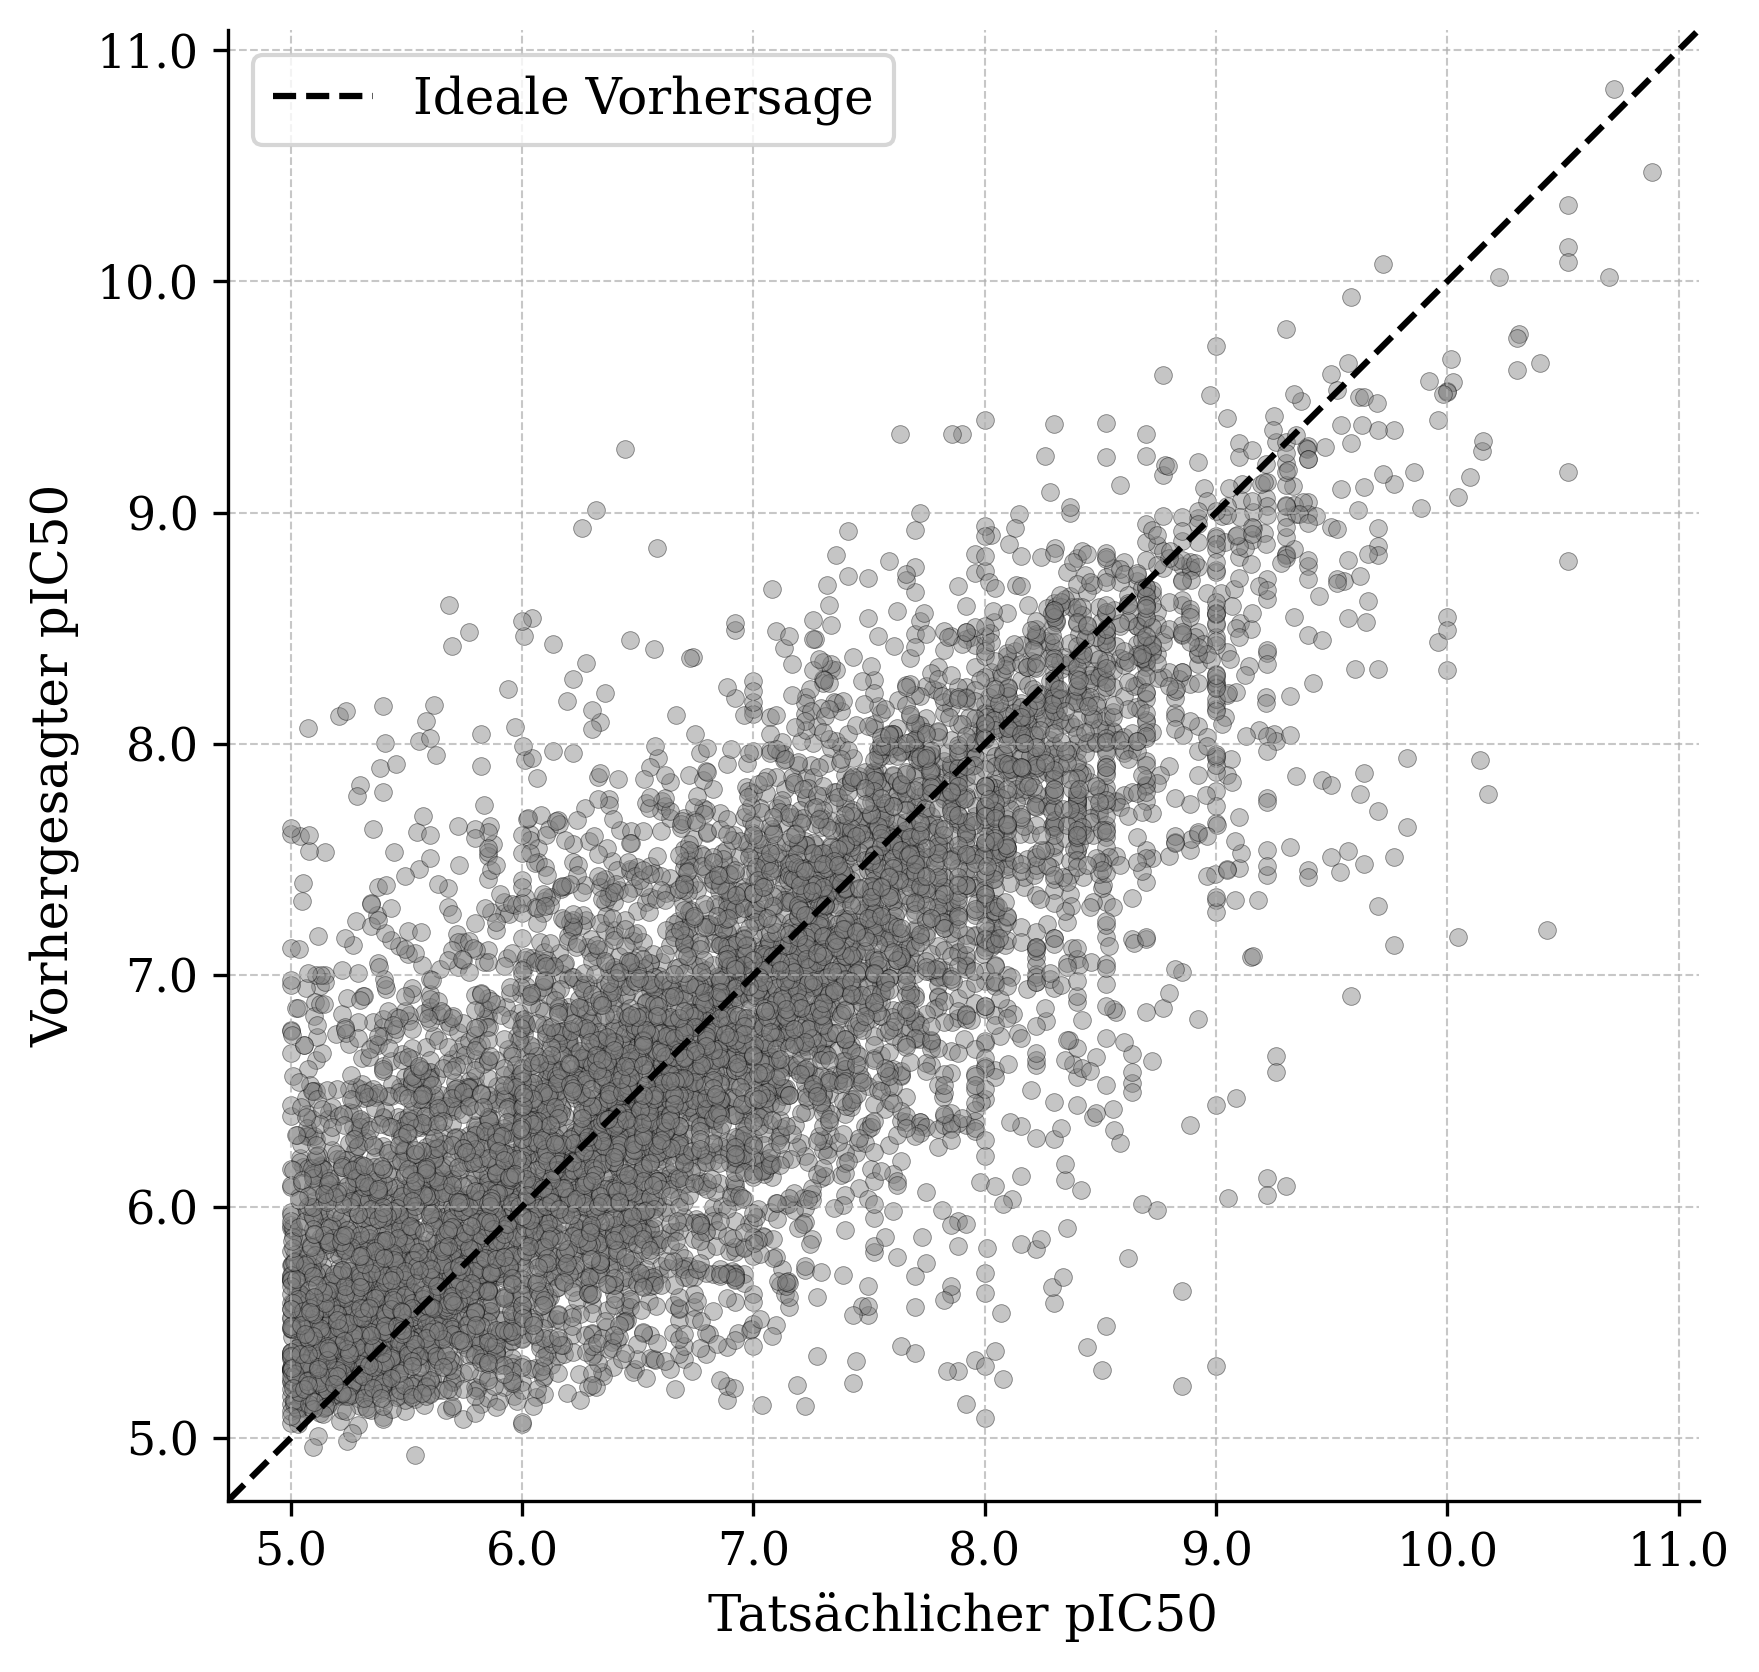

In [ ]:
from pathlib import Path
import os, sys
import torch
import mlflow
import pandas as pd
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
from matplotlib.ticker import StrMethodFormatter
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# -----------------------------
# Parameter des gewünschten Runs
# -----------------------------
MODEL_VARIANT = "baseline"
ENCODING_VARIANT = "baseline"
PROTEIN_MAX_LEN = "1200"
SMILES_MAX_LEN = "100"
IC50_LIMIT = "10000"

# -----------------------------
# MLflow konfigurieren
# -----------------------------
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

repo_path = Path("/content/drive/MyDrive/StudiumDataScience/Masterthesis/ColabRepository")
mlruns_path = repo_path / "mlruns"

sys.path.append(str(repo_path))
mlflow.set_tracking_uri(mlruns_path.as_uri())

runs = mlflow.search_runs(experiment_names=["dta_model_comparison"])
runs["metrics.test_mse"] = pd.to_numeric(runs["metrics.test_mse"], errors="coerce")

# -----------------------------
# Run auswählen
# -----------------------------
selected_runs = runs[
    (runs["params.model_variant"].astype(str) == MODEL_VARIANT) &
    (runs["params.encoding_variant"].astype(str) == ENCODING_VARIANT) &
    (runs["params.protein_max_len"].astype(str) == PROTEIN_MAX_LEN) &
    (runs["params.smiles_max_len"].astype(str) == SMILES_MAX_LEN) &
    (runs["params.ic50_upper_limit_nm"].astype(str) == IC50_LIMIT)
].copy()

if selected_runs.empty:
    raise ValueError("Kein Run mit diesen Parametern gefunden.")

selected_run = selected_runs.sort_values("metrics.test_mse").iloc[0]
run_id = selected_run["run_id"]

print("Ausgewählter Run")
print("Run ID:", run_id)
print("Run Name:", selected_run.get("tags.mlflow.runName", ""))
print("Model Variant:", selected_run.get("params.model_variant", ""))
print("Encoding Variant:", selected_run.get("params.encoding_variant", ""))
print("SMILES max len:", selected_run.get("params.smiles_max_len", ""))
print("Protein max len:", selected_run.get("params.protein_max_len", ""))
print("IC50 upper limit:", selected_run.get("params.ic50_upper_limit_nm", ""))
print("Logged Test MSE:", selected_run.get("metrics.test_mse", ""))

# -----------------------------
# Modell und Testdaten laden
# -----------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = mlflow.pytorch.load_model(f"runs:/{run_id}/model").to(device)
model.eval()

test_path = ENCODING_CONFIGS[ENCODING_VARIANT]["test_path"]
test_data = torch.load(test_path, map_location="cpu")

assert str(test_data["X_smiles"].shape[1]) == SMILES_MAX_LEN, "SMILES-Länge passt nicht zum Run."
assert str(test_data["X_protein"].shape[1]) == PROTEIN_MAX_LEN, "Proteinlänge passt nicht zum Run."

test_loader = DataLoader(
    TensorDataset(test_data["X_smiles"], test_data["X_protein"], test_data["y"]),
    batch_size=128,
    shuffle=False
)

# -----------------------------
# Nur Inference, kein Training
# -----------------------------
all_true, all_preds = [], []

with torch.no_grad():
    for smiles_batch, protein_batch, y_batch in test_loader:
        preds = model(smiles_batch.to(device), protein_batch.to(device))
        all_preds.extend(preds.cpu().numpy().flatten())
        all_true.extend(y_batch.numpy().flatten())

pred_df = pd.DataFrame({
    "actual_pic50": all_true,
    "predicted_pic50": all_preds
})

print("Berechneter Test MSE:", mean_squared_error(all_true, all_preds))
print("Berechneter Test MAE:", mean_absolute_error(all_true, all_preds))
print("Berechneter Test R²:", r2_score(all_true, all_preds))

# -----------------------------
# Plot: vorhergesagt vs. tatsächlich
# -----------------------------
min_val = min(pred_df["actual_pic50"].min(), pred_df["predicted_pic50"].min()) - 0.2
max_val = max(pred_df["actual_pic50"].max(), pred_df["predicted_pic50"].max()) + 0.2

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "font.size": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "figure.dpi": 300
})

fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(
    pred_df["actual_pic50"],
    pred_df["predicted_pic50"],
    color="grey",
    edgecolor="black",
    linewidth=0.2,
    alpha=0.45,
    s=18
)

ax.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Ideale Vorhersage"
)

ax.set_xlabel("Tatsächlicher pIC50")
ax.set_ylabel("Vorhergesagter pIC50")
ax.set_xlim(min_val, max_val)
ax.set_ylim(min_val, max_val)
ax.set_aspect("equal", adjustable="box")

ax.grid(axis="both", linestyle="--", linewidth=0.5, alpha=0.7)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.1f}"))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.1f}"))
ax.legend()

plt.tight_layout()
plt.show()

Run ID: d9bd30c68a5647b98ac1fa690c7fe0eb
Run Name: AttentionDTA_Baseline_baseline
Model Variant: baseline
Encoding Variant: baseline
SMILES max len: 100
Protein max len: 1200
IC50 upper limit: 10000
Test MSE: 0.4994659921300756
   epoch  train_mse  valid_mse
0      1   1.306728   0.902094
1      2   0.845594   0.782467
2      3   0.768487   0.953379
3      4   0.695279   0.703802
4      5   0.645659   0.720328


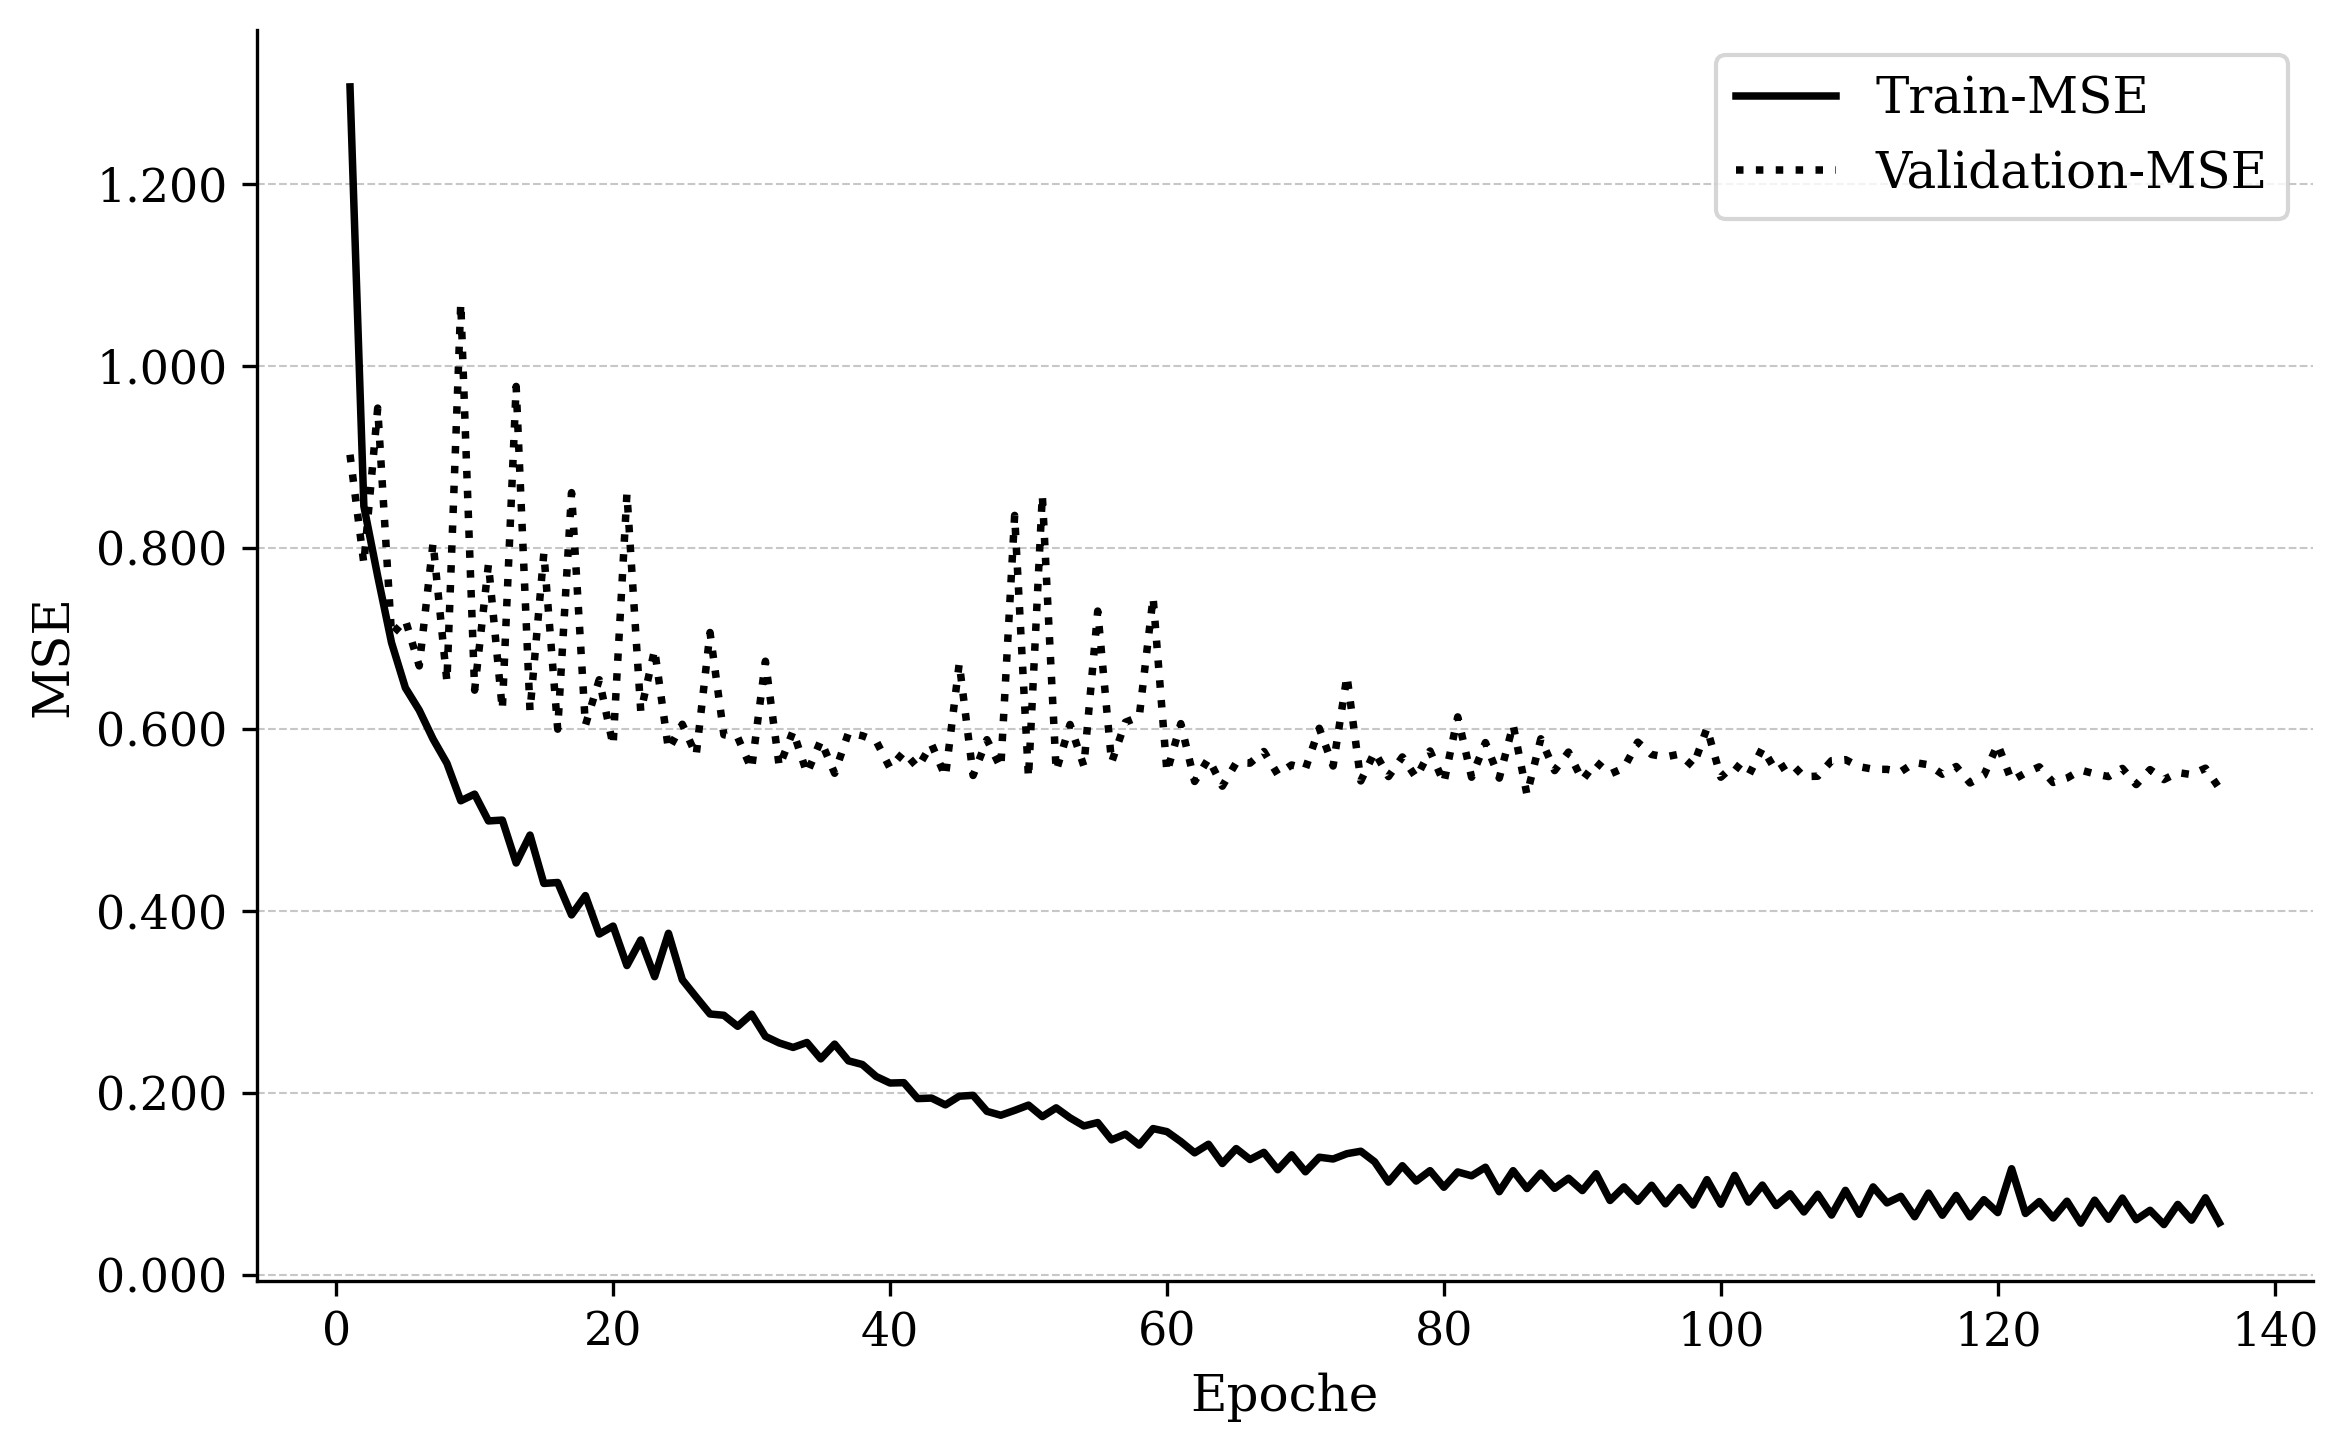

In [ ]:
from pathlib import Path
import mlflow
from mlflow.tracking import MlflowClient
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# MLflow Tracking URI setzen
mlruns_path = Path("/content/drive/MyDrive/StudiumDataScience/Masterthesis/ColabRepository/mlruns")
mlflow.set_tracking_uri(mlruns_path.as_uri())

client = MlflowClient()

# Beispiel: besten Run nach Test-MSE auswählen
runs["metrics.test_mse"] = pd.to_numeric(runs["metrics.test_mse"], errors="coerce")

selected_run = runs[
    (runs["params.model_variant"].astype(str) == "baseline") &
    (runs["params.encoding_variant"].astype(str) == "baseline") &
    (runs["params.protein_max_len"].astype(str) == "1200") &
    (runs["params.smiles_max_len"].astype(str) == "100") &
    (runs["params.ic50_upper_limit_nm"].astype(str) == "10000")
].sort_values("metrics.test_mse").iloc[0]

run_id = selected_run["run_id"]

print("Run ID:", run_id)
print("Run Name:", selected_run["tags.mlflow.runName"])
print("Model Variant:", selected_run["params.model_variant"])
print("Encoding Variant:", selected_run["params.encoding_variant"])
print("SMILES max len:", selected_run["params.smiles_max_len"])
print("Protein max len:", selected_run["params.protein_max_len"])
print("IC50 upper limit:", selected_run["params.ic50_upper_limit_nm"])
print("Test MSE:", selected_run["metrics.test_mse"])


# Metric History laden
train_history = client.get_metric_history(run_id, "train_mse")
valid_history = client.get_metric_history(run_id, "valid_mse")

# In DataFrames umwandeln
train_df = pd.DataFrame([
    {"epoch": metric.step, "train_mse": metric.value}
    for metric in train_history
])

valid_df = pd.DataFrame([
    {"epoch": metric.step, "valid_mse": metric.value}
    for metric in valid_history
])

# Zusammenführen
history_df = pd.merge(train_df, valid_df, on="epoch", how="outer")
history_df = history_df.sort_values("epoch")

print(history_df.head())

# Schriftart und Layout
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "figure.dpi": 300
})

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    history_df["epoch"],
    history_df["train_mse"],
    label="Train-MSE",
    color="black",
    linestyle="-",
    linewidth=1.8
)

ax.plot(
    history_df["epoch"],
    history_df["valid_mse"],
    label="Validation-MSE",
    color="black",
    linestyle="dotted",
    linewidth=1.8
)

ax.set_xlabel("Epoche")
ax.set_ylabel("MSE")

ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.7)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.3f}"))

ax.legend()

plt.tight_layout()
plt.show()

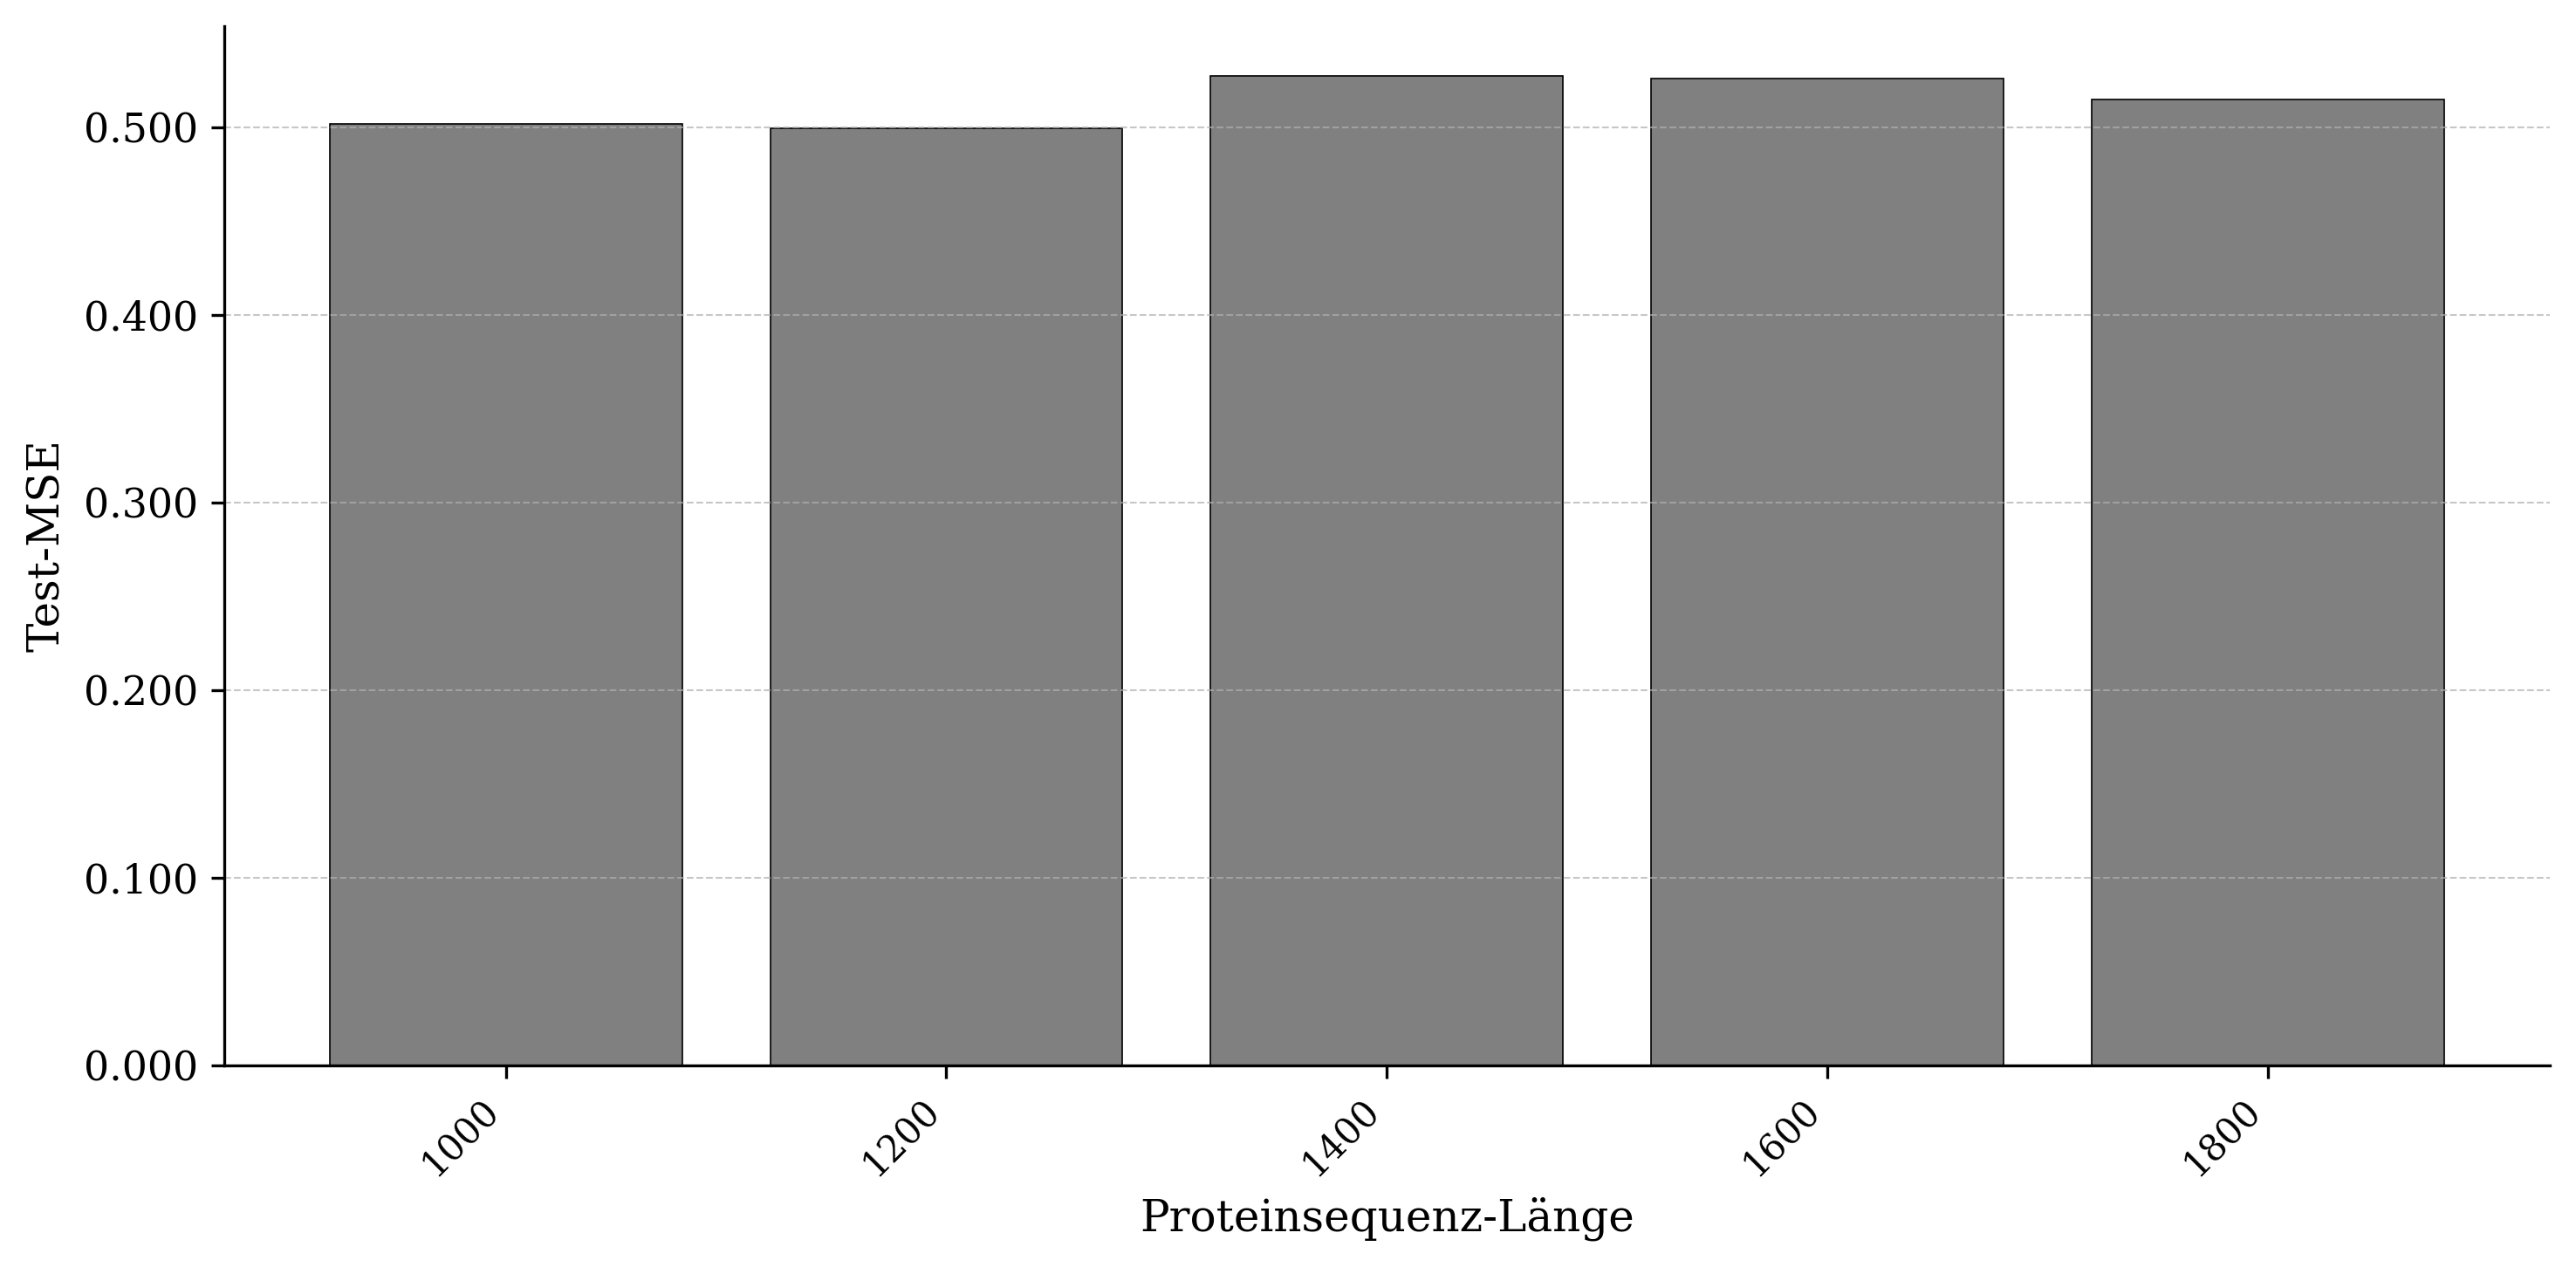

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

runs_ic50_protein_length = runs[
    (runs["params.smiles_max_len"].astype(str) == "100") &
    (runs["params.ic50_upper_limit_nm"].astype(str) == "10000") &
    (runs["params.model_variant"].astype(str) == "baseline") &
    (runs["params.encoding_variant"].astype(str) == "baseline")
].copy()

# Nach protein_max_len sortieren
runs_ic50_protein_length = runs_ic50_protein_length.sort_values("params.protein_max_len")

# Lesbare Modellnamen erstellen
runs_ic50_protein_length["run_label"] = (runs_ic50_protein_length["params.protein_max_len"].astype(str))

# Schriftart und Layout
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 11,
    "figure.dpi": 300
})

# Barplot
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    runs_ic50_protein_length["run_label"],
    runs_ic50_protein_length["metrics.test_mse"],
    color="grey",
    edgecolor="black",
    linewidth=0.4
)

ax.set_xlabel("Proteinsequenz-Länge")
ax.set_ylabel("Test-MSE")

# Labels drehen
plt.xticks(rotation=45, ha="right")

# Dezente horizontale Hilfslinien
ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.7)

# Obere und rechte Rahmenlinie entfernen
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Keine wissenschaftliche Schreibweise
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.3f}"))

plt.tight_layout()

plt.show()

Anzahl gefilterter Runs: 5


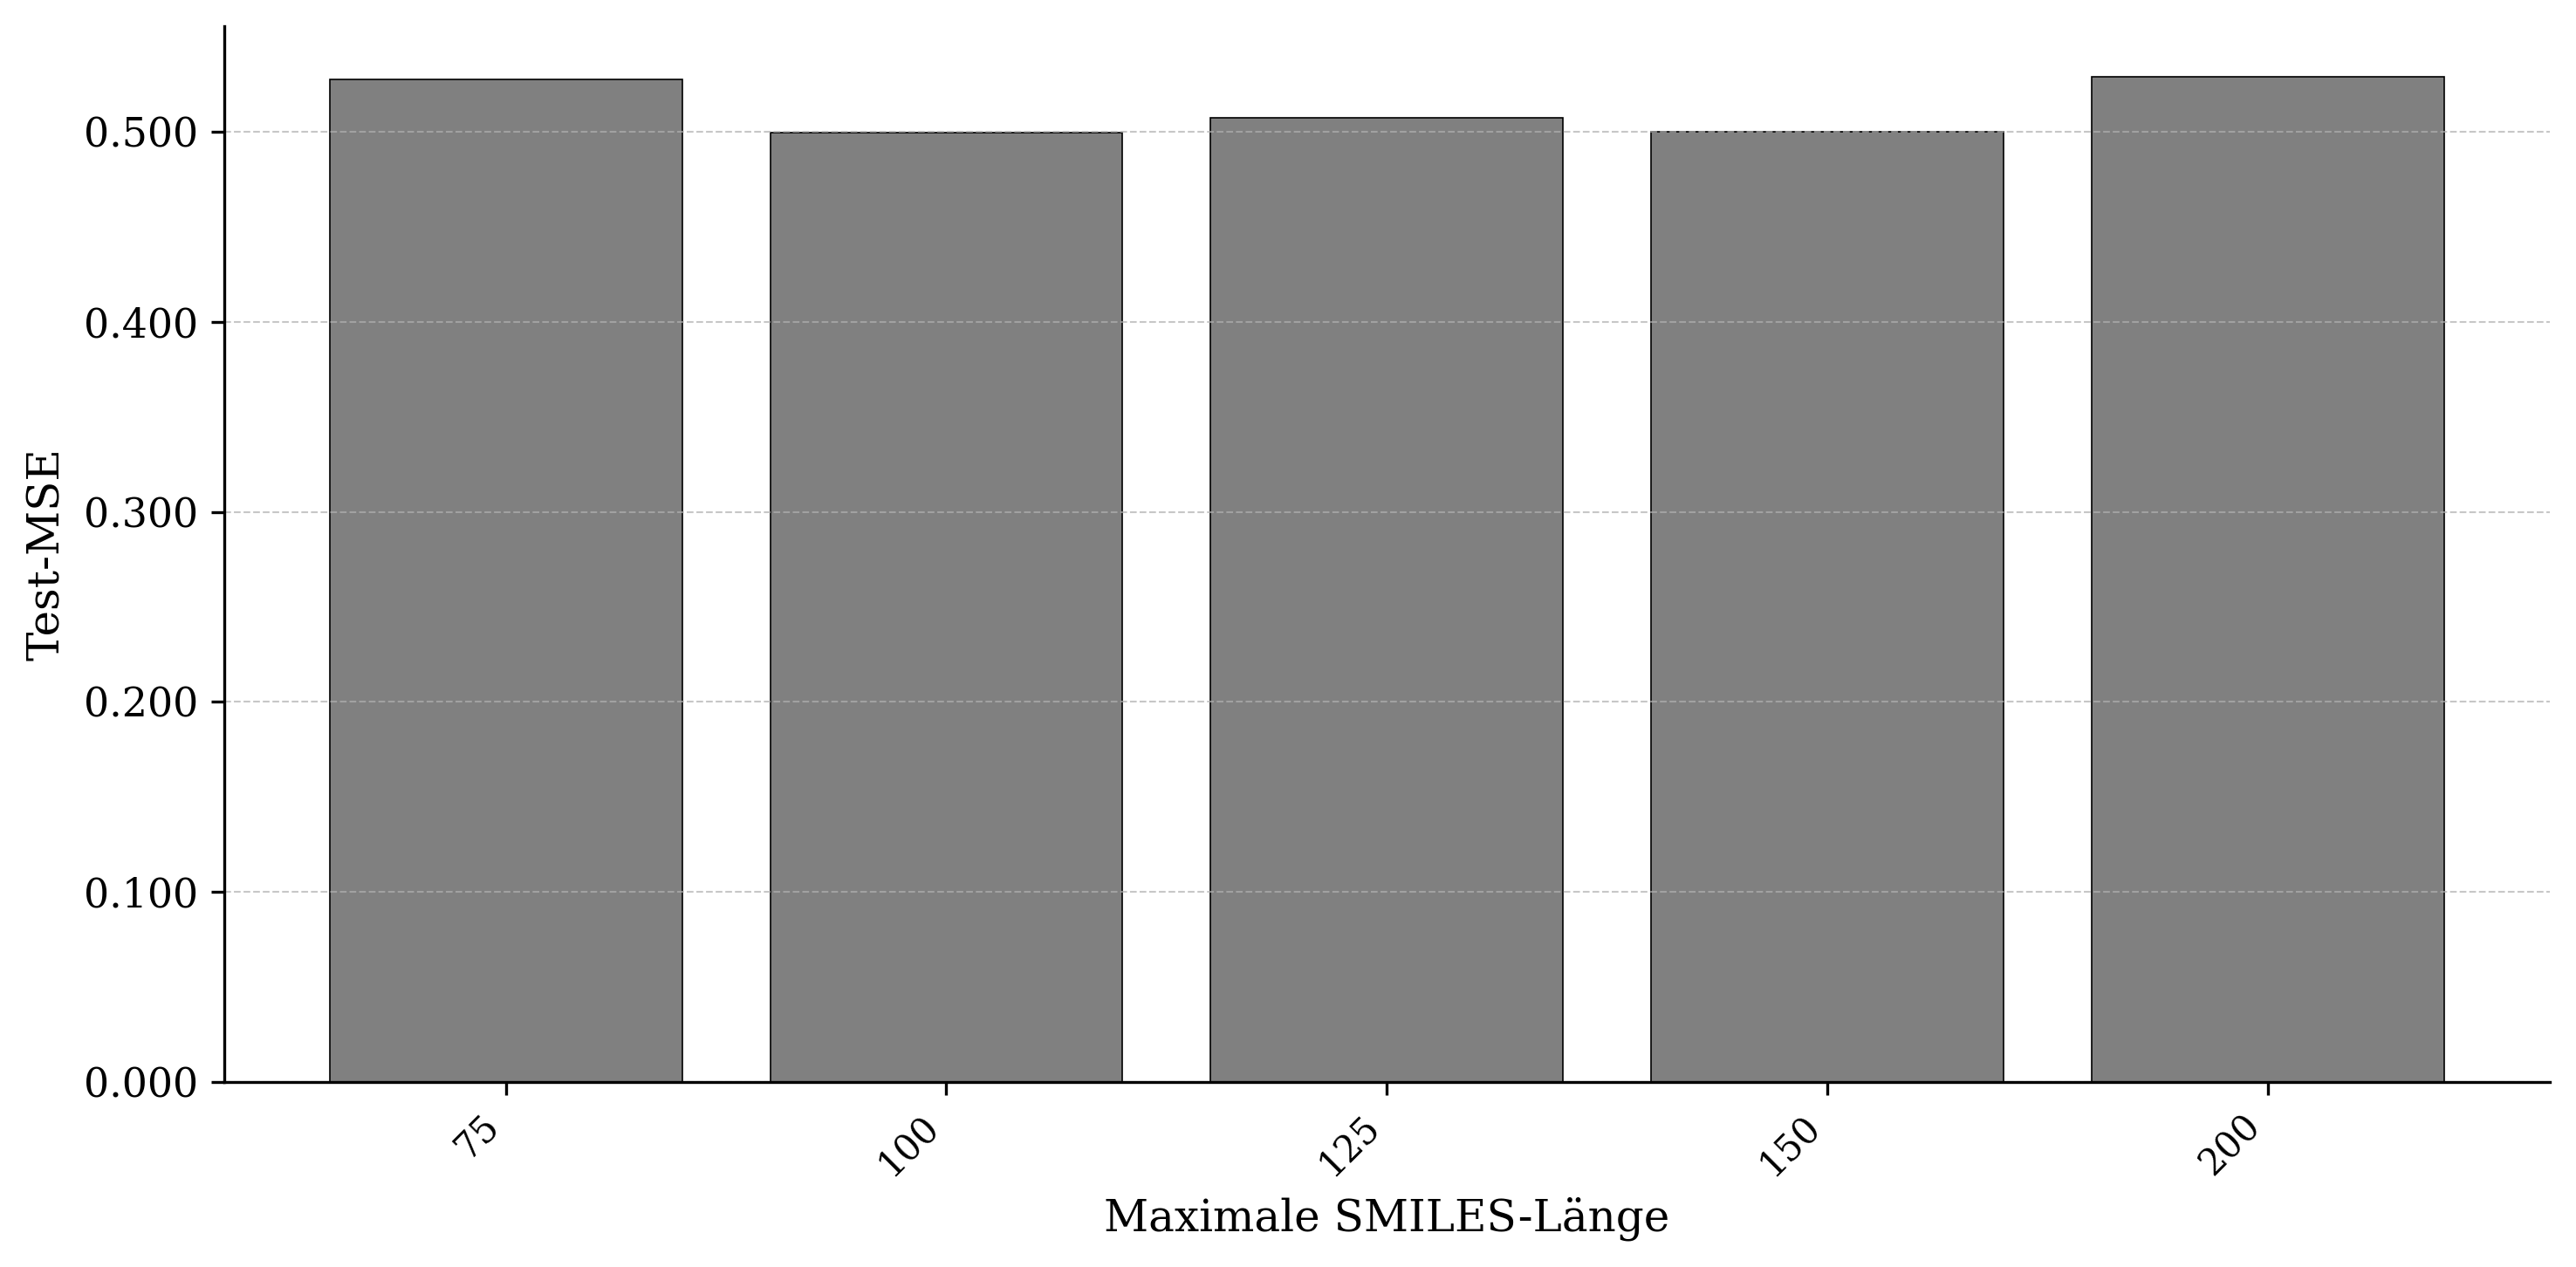

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Sicherstellen, dass test_mse numerisch ist
runs["metrics.test_mse"] = pd.to_numeric(
    runs["metrics.test_mse"],
    errors="coerce"
)

# DataFrame filtern:
# Proteinlänge 1200, IC50-Limit 10000, Modell baseline
runs_ic50_smiles_length = runs[
    (runs["params.protein_max_len"].astype(str) == "1200") &
    (runs["params.ic50_upper_limit_nm"].astype(str) == "10000") &
    (runs["params.model_variant"].astype(str) == "baseline") &
    (runs["params.encoding_variant"].astype(str) == "baseline")
].copy()

# SMILES-Länge numerisch machen
runs_ic50_smiles_length["smiles_max_len_num"] = pd.to_numeric(
    runs_ic50_smiles_length["params.smiles_max_len"],
    errors="coerce"
)

# Test-MSE numerisch machen
runs_ic50_smiles_length["test_mse_num"] = pd.to_numeric(
    runs_ic50_smiles_length["metrics.test_mse"],
    errors="coerce"
)

# Zeilen ohne SMILES-Länge oder Test-MSE entfernen
runs_ic50_smiles_length = runs_ic50_smiles_length.dropna(
    subset=["smiles_max_len_num", "test_mse_num"]
)

# Nach numerischer SMILES-Länge sortieren
runs_ic50_smiles_length = runs_ic50_smiles_length.sort_values("smiles_max_len_num")

# Lesbare Labels
runs_ic50_smiles_length["run_label"] = (
    runs_ic50_smiles_length["smiles_max_len_num"]
    .astype(int)
    .astype(str)
)

# Prüfen, wie viele Runs geplottet werden
print("Anzahl gefilterter Runs:", len(runs_ic50_smiles_length))

# Schriftart und Layout
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 11,
    "figure.dpi": 300
})

# Barplot
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    runs_ic50_smiles_length["run_label"],
    runs_ic50_smiles_length["test_mse_num"],
    color="grey",
    edgecolor="black",
    linewidth=0.4
)

ax.set_xlabel("Maximale SMILES-Länge")
ax.set_ylabel("Test-MSE")

plt.xticks(rotation=45, ha="right")

ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.7)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.3f}"))

plt.tight_layout()
plt.show()

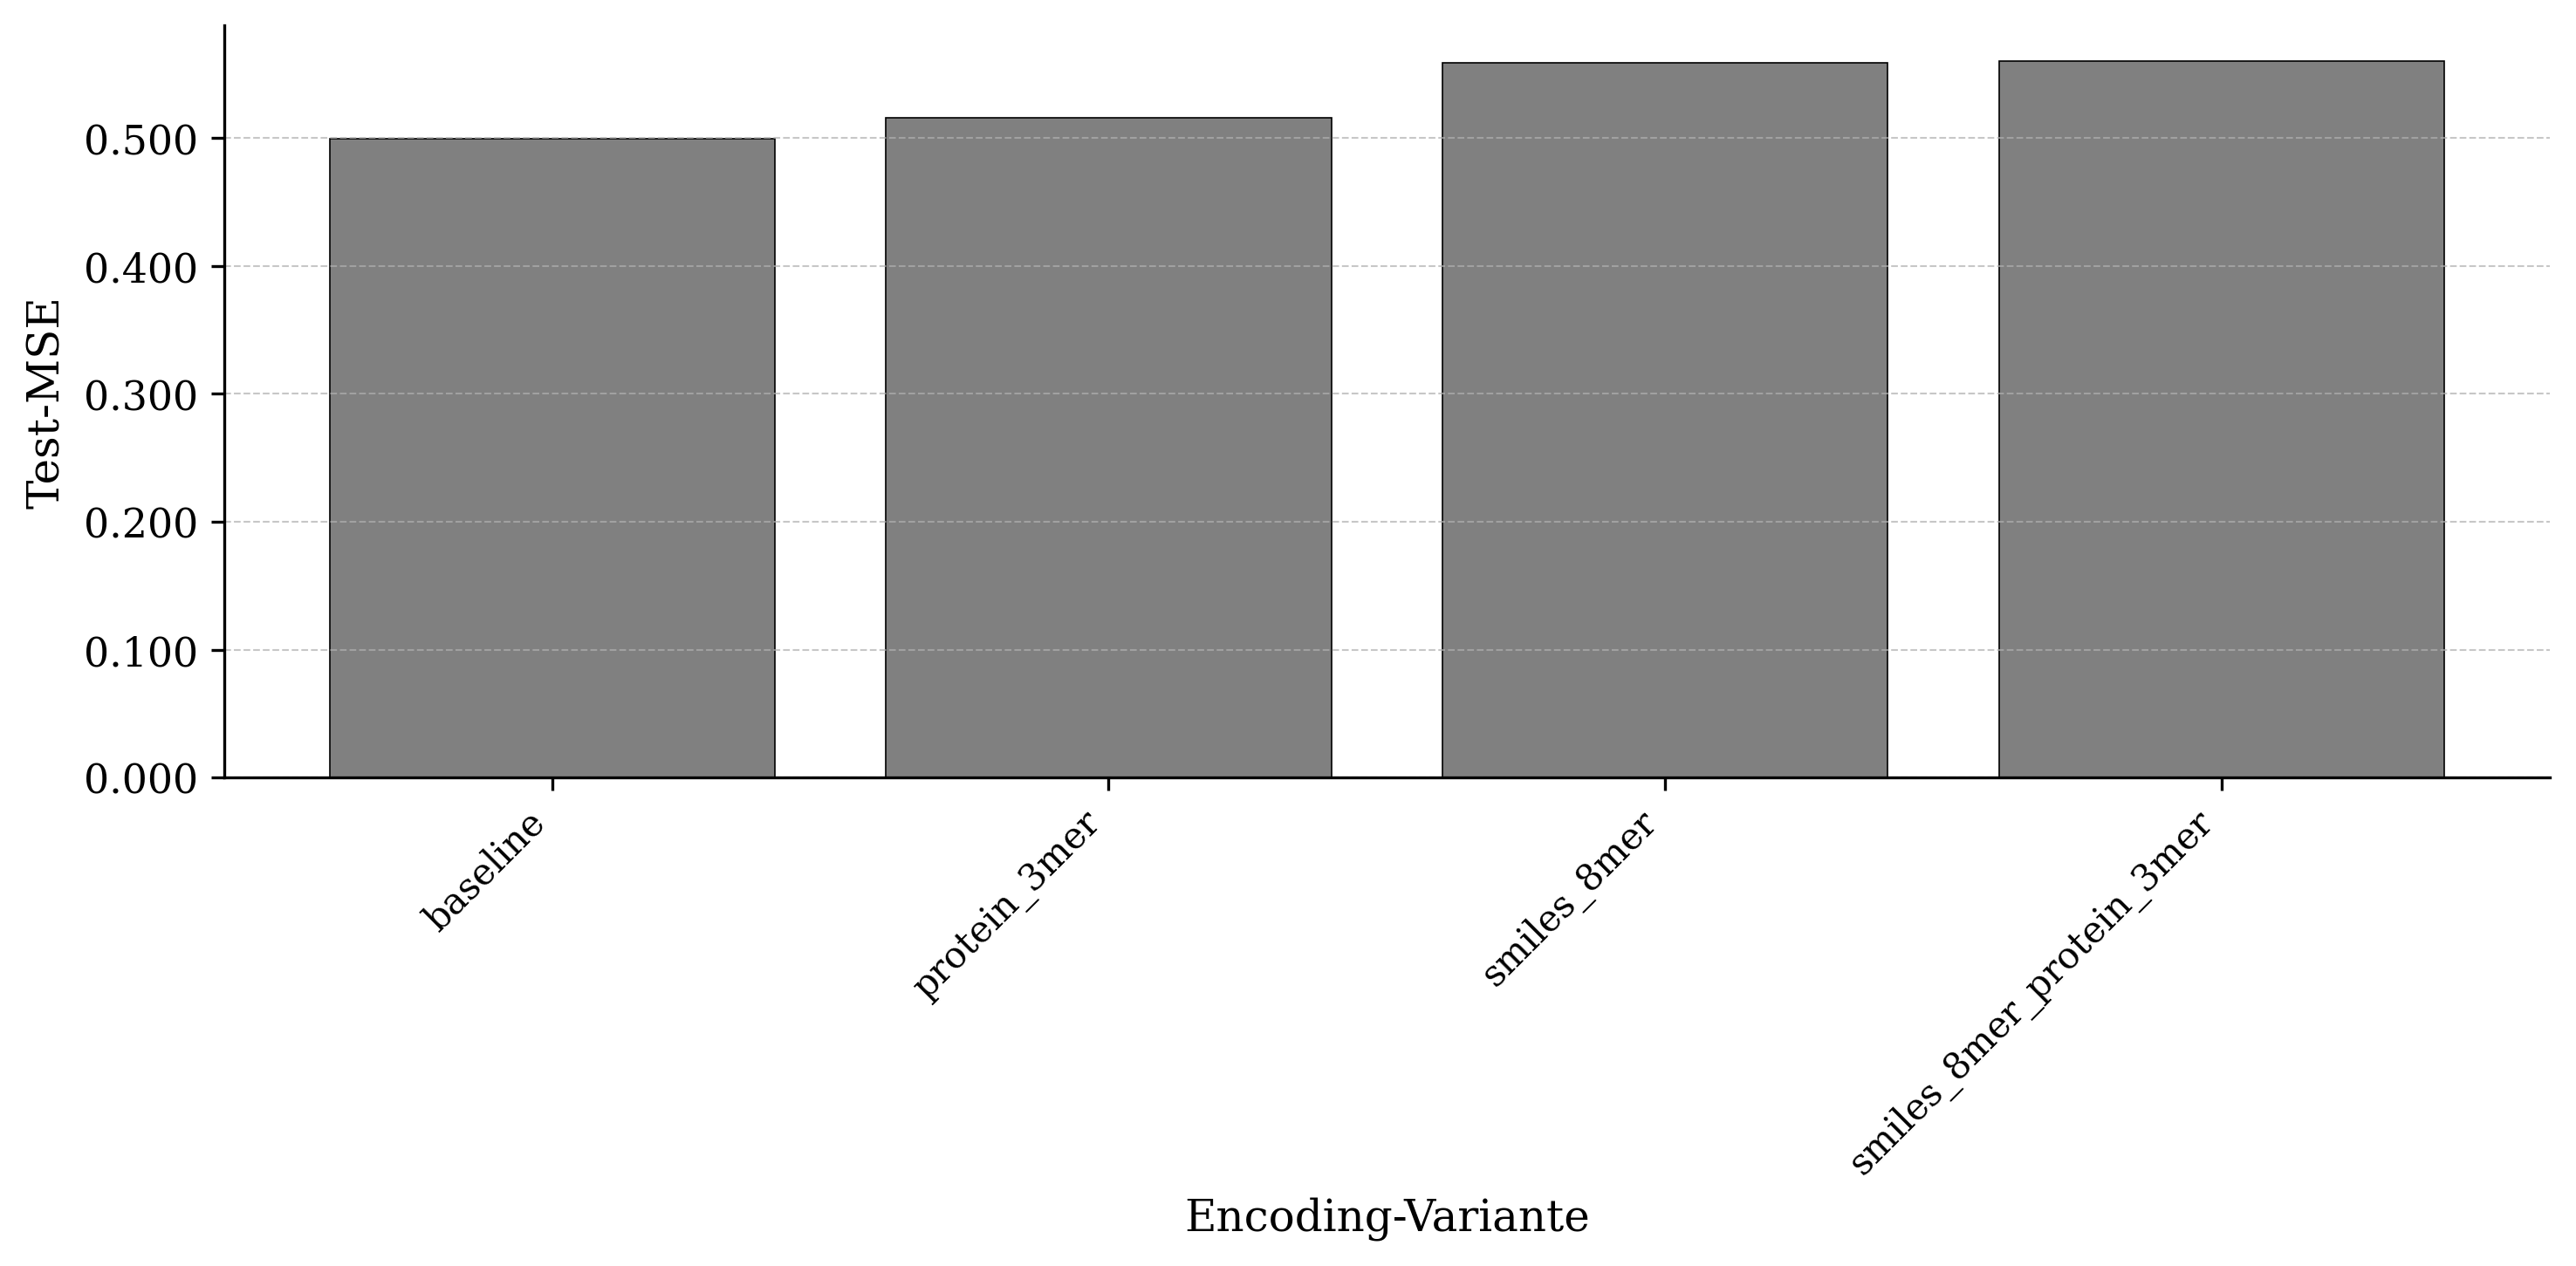

In [ ]:
# DataFrame filtern: Proteinlänge 1200 UND IC50-Limit 10000 und SMILES Länge 100, Modell baseline
runs_ic50_10000_baseline = runs[
    (runs["params.protein_max_len"].astype(str) == "1200") &
    (runs["params.smiles_max_len"].astype(str) == "100") &
    (runs["params.ic50_upper_limit_nm"].astype(str) == "10000") &
    (runs["params.model_variant"].astype(str) == "baseline")
].copy()

# Gewünschte Reihenfolge der Encoding-Varianten
encoding_order = [
    "baseline",
    "protein_3mer",
    "smiles_8mer",
    "smiles_8mer_protein_3mer"
]

# Encoding-Variante als geordnete Kategorie setzen
runs_ic50_10000_baseline["encoding_ordered"] = pd.Categorical(
    runs_ic50_10000_baseline["params.encoding_variant"],
    categories=encoding_order,
    ordered=True
)

# Nach gewünschter Encoding-Reihenfolge sortieren
runs_ic50_10000_baseline = runs_ic50_10000_baseline.sort_values("encoding_ordered")

# Schriftart und Layout
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 11,
    "figure.dpi": 300
})

# Barplot
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    runs_ic50_10000_baseline["params.encoding_variant"],
    runs_ic50_10000_baseline["metrics.test_mse"],
    color="grey",
    edgecolor="black",
    linewidth=0.4
)

ax.set_xlabel("Encoding-Variante")
ax.set_ylabel("Test-MSE")

plt.xticks(rotation=45, ha="right")

ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.7)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.3f}"))

plt.tight_layout()
plt.show()

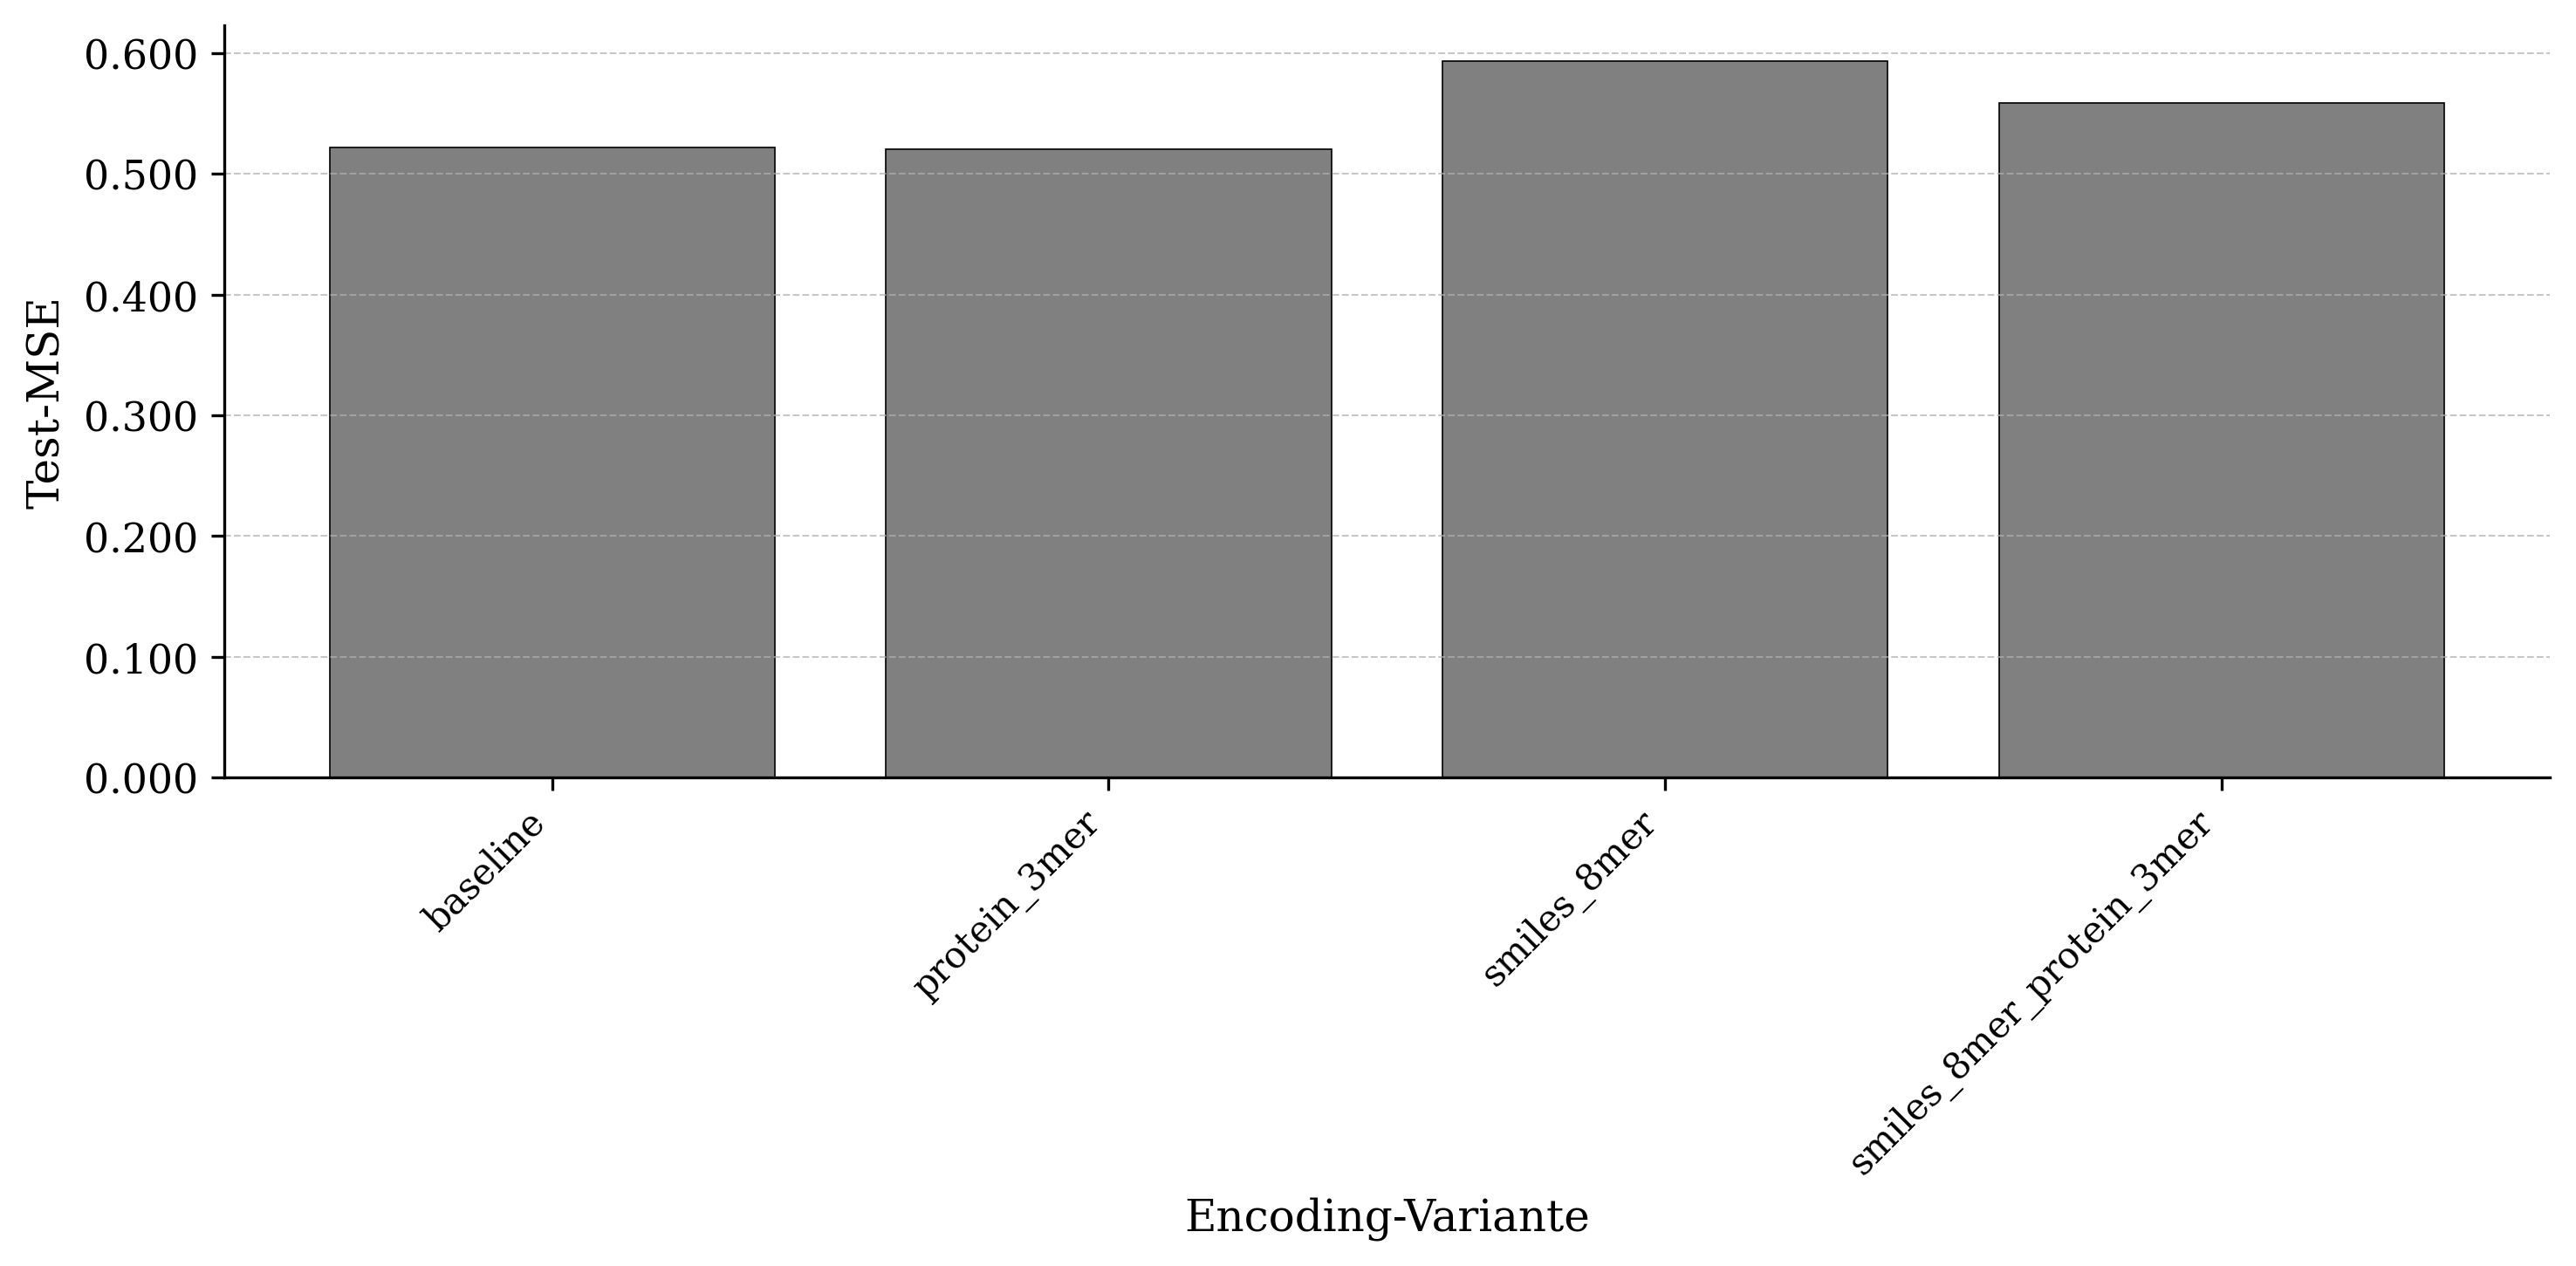

In [ ]:
# DataFrame filtern: Proteinlänge 1200 UND IC50-Limit 10000 und SMILES Länge 100 Modell bilstm
runs_ic50_10000_bilstm = runs[
    (runs["params.protein_max_len"].astype(str) == "1200") &
    (runs["params.smiles_max_len"].astype(str) == "100") &
    (runs["params.ic50_upper_limit_nm"].astype(str) == "10000") &
    (runs["params.model_variant"].astype(str) == "bilstm")
].copy()


# Gewünschte Reihenfolge der Encoding-Varianten
encoding_order = [
    "baseline",
    "protein_3mer",
    "smiles_8mer",
    "smiles_8mer_protein_3mer"
]

# Encoding-Variante als geordnete Kategorie setzen
runs_ic50_10000_bilstm["encoding_ordered"] = pd.Categorical(
    runs_ic50_10000_bilstm["params.encoding_variant"],
    categories=encoding_order,
    ordered=True
)

# Nach gewünschter Encoding-Reihenfolge sortieren
runs_ic50_10000_bilstm = runs_ic50_10000_bilstm.sort_values("encoding_ordered")


# Schriftart und Layout
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 11,
    "figure.dpi": 300
})

# Barplot
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    runs_ic50_10000_bilstm["params.encoding_variant"],
    runs_ic50_10000_bilstm["metrics.test_mse"],
    color="grey",
    edgecolor="black",
    linewidth=0.4
)

ax.set_xlabel("Encoding-Variante")
ax.set_ylabel("Test-MSE")

plt.xticks(rotation=45, ha="right")

ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.7)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.3f}"))

plt.tight_layout()
plt.show()

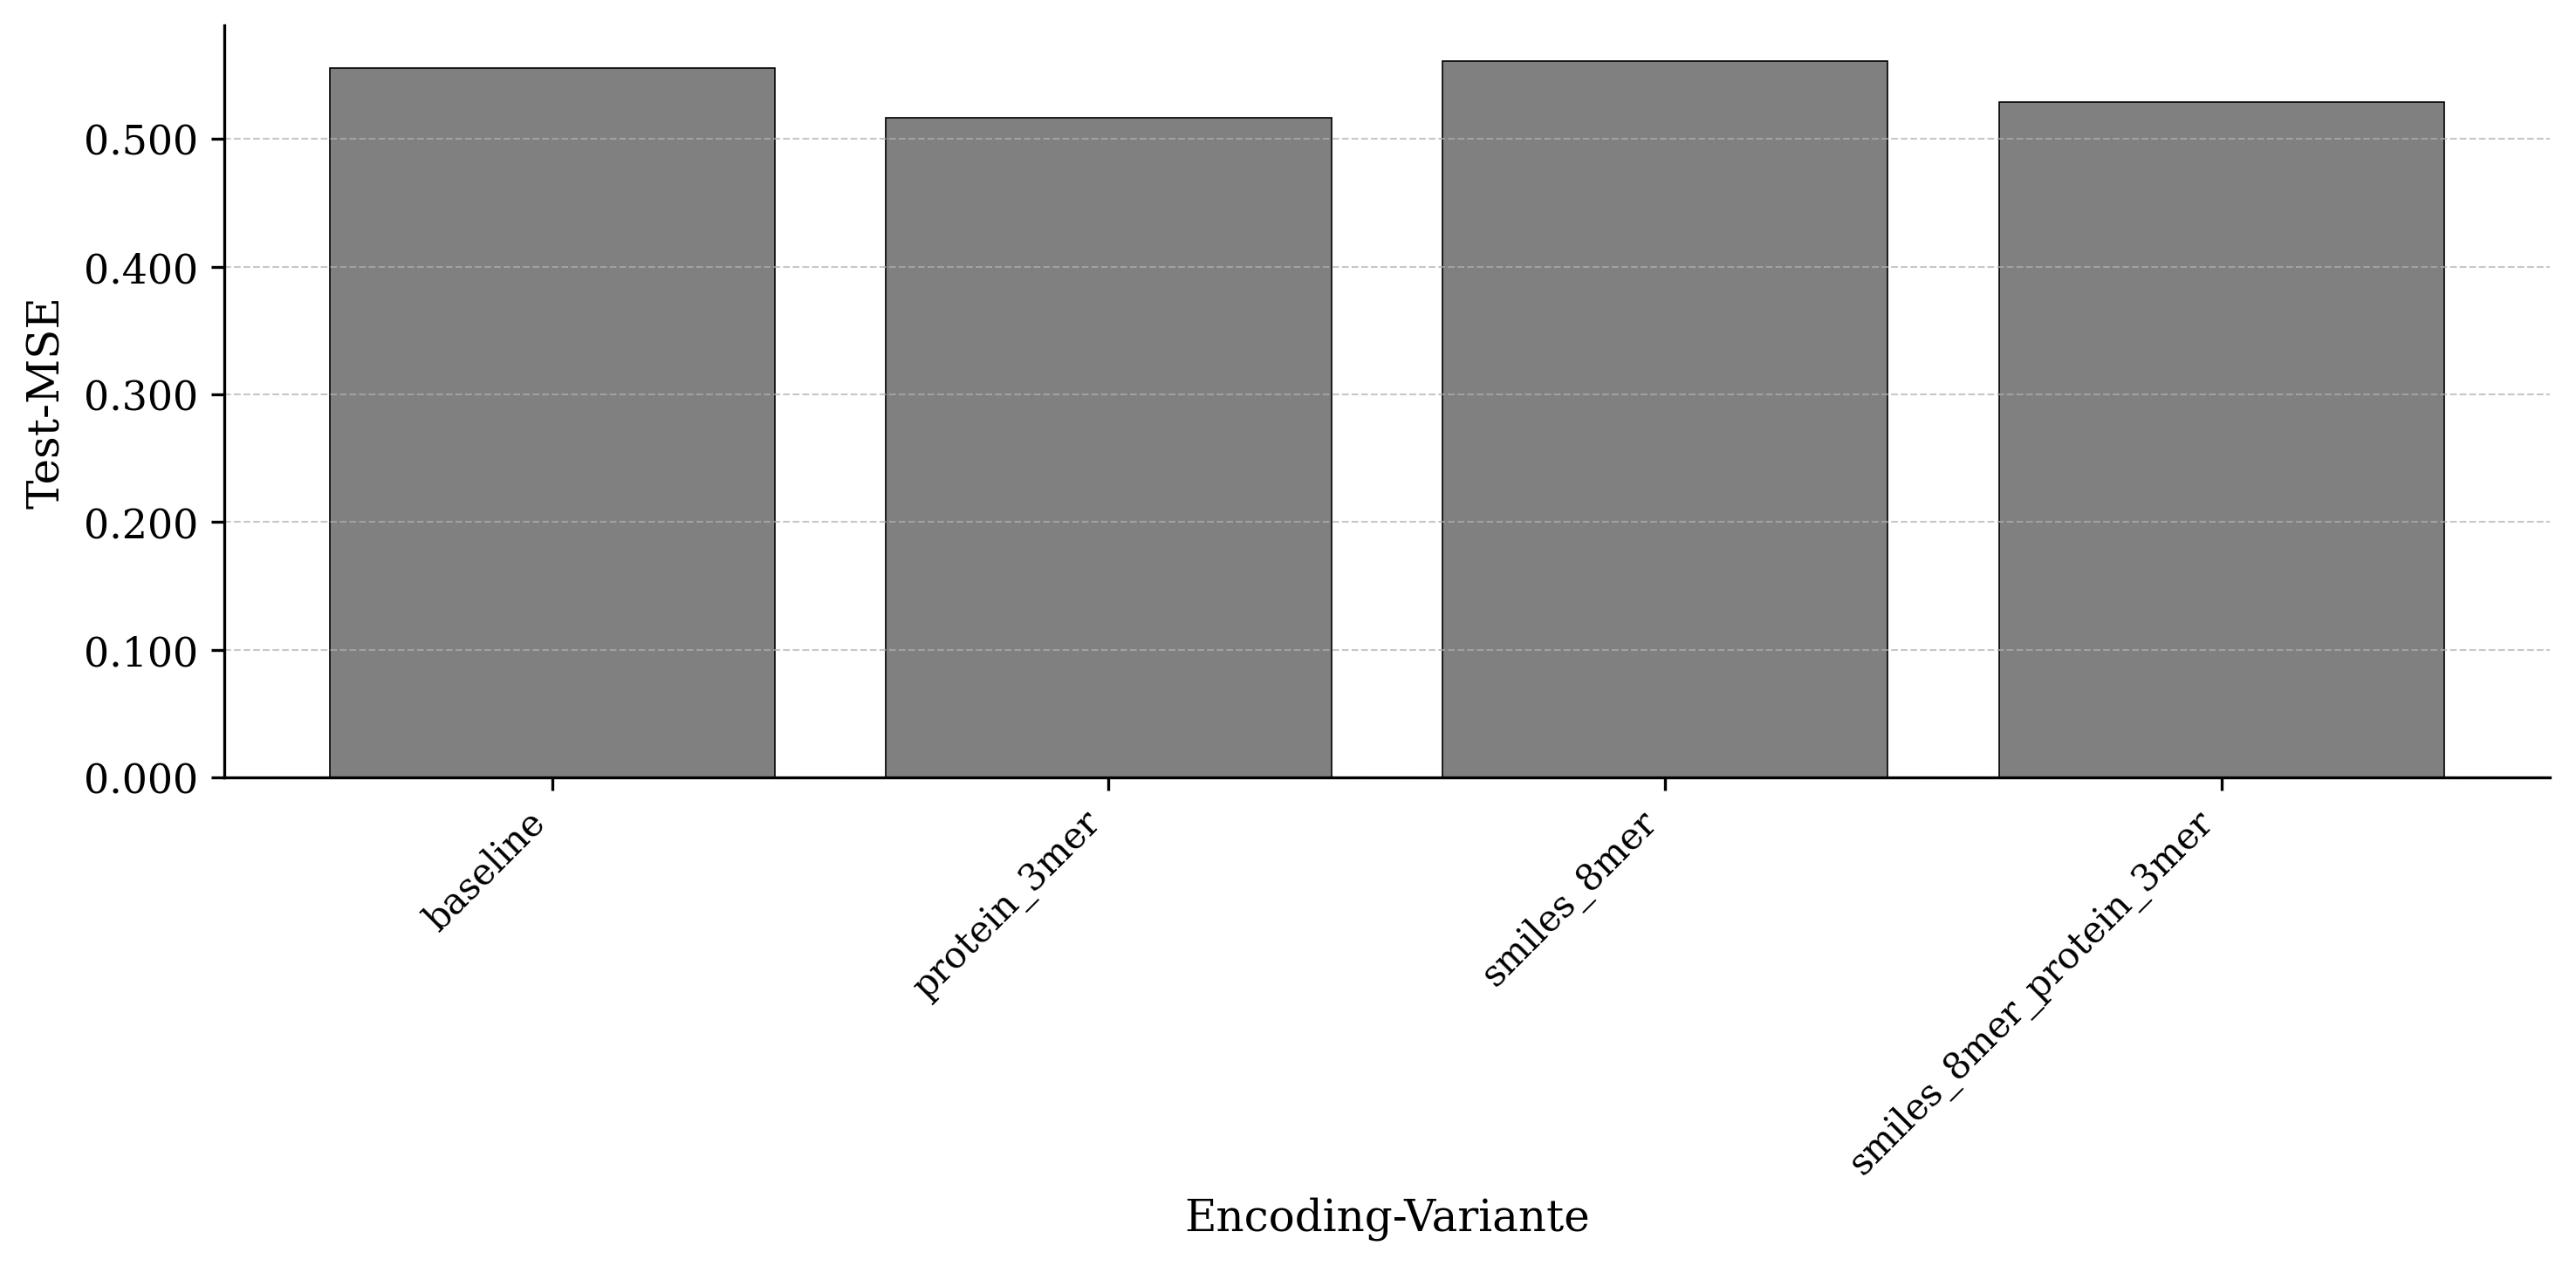

In [ ]:
# DataFrame filtern: Proteinlänge 1200 UND IC50-Limit 10000 und SMILES Länge 100, Modell inception
runs_ic50_10000_inception = runs[
    (runs["params.protein_max_len"].astype(str) == "1200") &
    (runs["params.smiles_max_len"].astype(str) == "100") &
    (runs["params.ic50_upper_limit_nm"].astype(str) == "10000") &
    (runs["params.model_variant"].astype(str) == "inception")
].copy()

# Gewünschte Reihenfolge der Encoding-Varianten
encoding_order = [
    "baseline",
    "protein_3mer",
    "smiles_8mer",
    "smiles_8mer_protein_3mer"
]

# Encoding-Variante als geordnete Kategorie setzen
runs_ic50_10000_inception["encoding_ordered"] = pd.Categorical(
    runs_ic50_10000_inception["params.encoding_variant"],
    categories=encoding_order,
    ordered=True
)

# Nach gewünschter Encoding-Reihenfolge sortieren
runs_ic50_10000_inception = runs_ic50_10000_inception.sort_values("encoding_ordered")

# Schriftart und Layout
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 11,
    "figure.dpi": 300
})

# Barplot
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    runs_ic50_10000_inception["params.encoding_variant"],
    runs_ic50_10000_inception["metrics.test_mse"],
    color="grey",
    edgecolor="black",
    linewidth=0.4
)

ax.set_xlabel("Encoding-Variante")
ax.set_ylabel("Test-MSE")

plt.xticks(rotation=45, ha="right")

ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.7)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.3f}"))

plt.tight_layout()
plt.show()

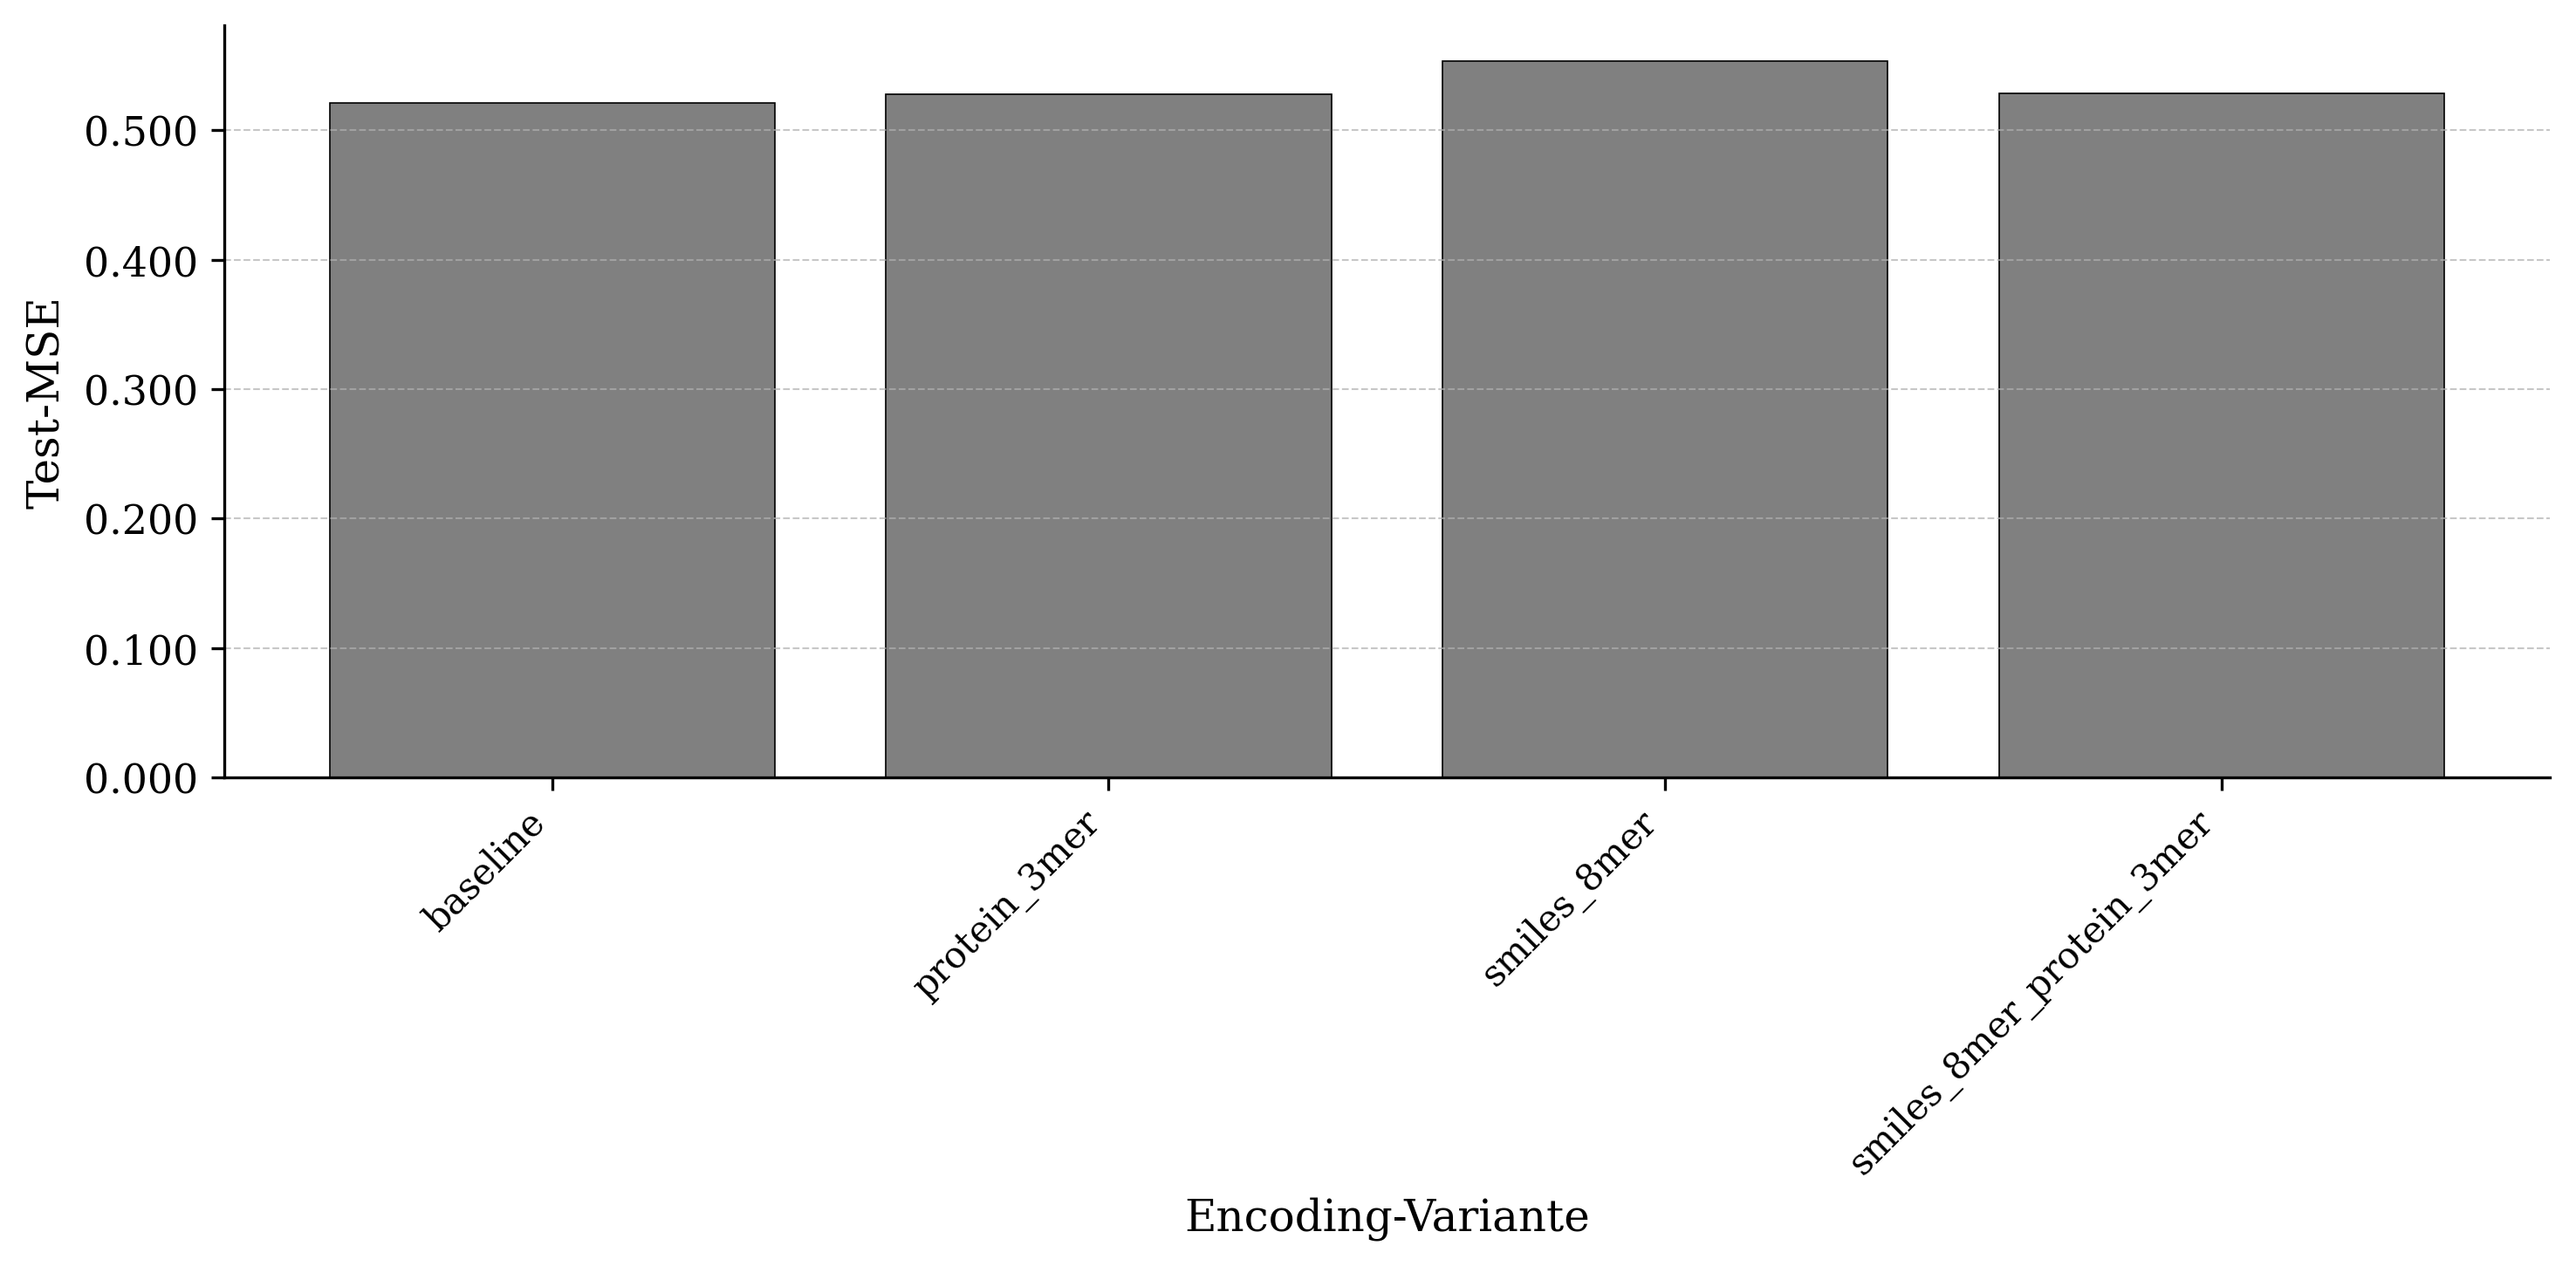

In [ ]:
# DataFrame filtern: Proteinlänge 1200 UND IC50-Limit 10000 und SMILES Länge 100, Modell inception_bilstm
runs_ic50_10000_inception_bilstm = runs[
    (runs["params.protein_max_len"].astype(str) == "1200") &
    (runs["params.smiles_max_len"].astype(str) == "100") &
    (runs["params.ic50_upper_limit_nm"].astype(str) == "10000") &
    (runs["params.model_variant"].astype(str) == "inception_bilstm")
].copy()

# Gewünschte Reihenfolge der Encoding-Varianten
encoding_order = [
    "baseline",
    "protein_3mer",
    "smiles_8mer",
    "smiles_8mer_protein_3mer"
]

# Encoding-Variante als geordnete Kategorie setzen
runs_ic50_10000_inception_bilstm["encoding_ordered"] = pd.Categorical(
    runs_ic50_10000_inception_bilstm["params.encoding_variant"],
    categories=encoding_order,
    ordered=True
)

# Nach gewünschter Encoding-Reihenfolge sortieren
runs_ic50_10000_inception_bilstm = runs_ic50_10000_inception_bilstm.sort_values("encoding_ordered")

# Schriftart und Layout
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 11,
    "figure.dpi": 300
})

# Barplot
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    runs_ic50_10000_inception_bilstm["params.encoding_variant"],
    runs_ic50_10000_inception_bilstm["metrics.test_mse"],
    color="grey",
    edgecolor="black",
    linewidth=0.4
)

ax.set_xlabel("Encoding-Variante")
ax.set_ylabel("Test-MSE")

plt.xticks(rotation=45, ha="right")

ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.7)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.3f}"))

plt.tight_layout()
plt.show()